# Credit Card Fraud Detection Using Machine Learning

In [ ]:
# Run this installation cell once in Jupyter / Google Colab
!pip install -q pandas numpy matplotlib scikit-learn imbalanced-learn xgboost shap pyreadr

In [ ]:
# IMPORT PACKAGES

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyreadr
import shap

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    PredefinedSplit
)

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier


RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ============================================================
# 2. SET DATASET PATHS
# ============================================================

# Primary Fraud Detection Handbook dataset
# Your screenshot shows this folder contains all 183 .pkl files.

PRIMARY_DATA_PATH = Path(
    r"/content/drive/MyDrive/simulated-data-raw-main/data"
)

# ULB European Credit Card Fraud dataset
# CHANGE THIS LINE IF creditcard.Rdata IS IN ANOTHER FOLDER

ULB_PATH = Path(
    r"/content/drive/MyDrive/creditcard.Rdata"
)

In [ ]:
# ============================================================
# 3. LOAD PRIMARY FRAUD DETECTION HANDBOOK DATASET
# ============================================================

print("=" * 70)
print("LOADING PRIMARY FRAUD DETECTION HANDBOOK DATASET")
print("=" * 70)

pkl_files = sorted(PRIMARY_DATA_PATH.glob("*.pkl"))

print("Number of files found:", len(pkl_files))

if len(pkl_files) == 0:
    raise FileNotFoundError(
        "No .pkl files found. Check PRIMARY_DATA_PATH."
    )

print("First file:", pkl_files[0].name)
print("Last file:", pkl_files[-1].name)

primary_frames = []

for file in pkl_files:
    daily_data = pd.read_pickle(file)
    primary_frames.append(daily_data)

primary = pd.concat(
    primary_frames,
    ignore_index=True
)

del primary_frames

primary["TX_DATETIME"] = pd.to_datetime(
    primary["TX_DATETIME"]
)

primary = primary.sort_values(
    ["TX_DATETIME", "TRANSACTION_ID"]
).reset_index(drop=True)


print("\nPrimary dataset loaded successfully.")
print("Shape:", primary.shape)
print("\nFirst five rows:")
display(primary.head())

print("\nColumns:")
print(primary.columns.tolist())

LOADING PRIMARY FRAUD DETECTION HANDBOOK DATASET
Number of files found: 183
First file: 2018-04-01.pkl
Last file: 2018-09-30.pkl

Primary dataset loaded successfully.
Shape: (1754155, 9)

First five rows:


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO
0,0,2018-04-01 00:00:31,596,3156,57.16,31,0,0,0
1,1,2018-04-01 00:02:10,4961,3412,81.51,130,0,0,0
2,2,2018-04-01 00:07:56,2,1365,146.00,476,0,0,0
3,3,2018-04-01 00:09:29,4128,8737,64.49,569,0,0,0
4,4,2018-04-01 00:10:34,927,9906,50.99,634,0,0,0



Columns:
['TRANSACTION_ID', 'TX_DATETIME', 'CUSTOMER_ID', 'TERMINAL_ID', 'TX_AMOUNT', 'TX_TIME_SECONDS', 'TX_TIME_DAYS', 'TX_FRAUD', 'TX_FRAUD_SCENARIO']


In [ ]:
# ============================================================
# 4. PRIMARY DATASET INITIAL VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("PRIMARY DATASET VALIDATION")
print("=" * 70)

print("\nDataset dimensions:")
print("Rows:", primary.shape[0])
print("Columns:", primary.shape[1])

print("\nMissing values:")
print(primary.isnull().sum())

print("\nTotal missing values:")
print(primary.isnull().sum().sum())

print("\nExact duplicate rows:")
print(primary.duplicated().sum())

print("\nDuplicate Transaction IDs:")
print(primary["TRANSACTION_ID"].duplicated().sum())

print("\nTarget values:")
print(primary["TX_FRAUD"].value_counts())

print("\nTarget percentages:")
print(
    primary["TX_FRAUD"]
    .value_counts(normalize=True)
    .mul(100)
)

print("\nNegative transaction amounts:")
print((primary["TX_AMOUNT"] < 0).sum())

print("\nTransaction amount statistics:")
display(primary["TX_AMOUNT"].describe())


# Validate target

valid_target_values = set(
    primary["TX_FRAUD"]
    .dropna()
    .unique()
)

if not valid_target_values.issubset({0, 1}):
    raise ValueError(
        "TX_FRAUD contains invalid target values."
    )


# Remove missing essential observations

primary = primary.dropna(
    subset=[
        "TX_DATETIME",
        "TX_AMOUNT",
        "TX_FRAUD"
    ]
)


# Remove impossible negative transaction amounts

primary = primary[
    primary["TX_AMOUNT"] >= 0
].copy()


# Exact duplicate records can be removed because
# TRANSACTION_ID should uniquely identify a transaction.

primary = primary.drop_duplicates().reset_index(drop=True)


print("\nShape after basic cleaning:")
print(primary.shape)


PRIMARY DATASET VALIDATION

Dataset dimensions:
Rows: 1754155
Columns: 9

Missing values:
TRANSACTION_ID       0
TX_DATETIME          0
CUSTOMER_ID          0
TERMINAL_ID          0
TX_AMOUNT            0
TX_TIME_SECONDS      0
TX_TIME_DAYS         0
TX_FRAUD             0
TX_FRAUD_SCENARIO    0
dtype: int64

Total missing values:
0

Exact duplicate rows:
0

Duplicate Transaction IDs:
0

Target values:
TX_FRAUD
0    1739474
1      14681
Name: count, dtype: int64

Target percentages:
TX_FRAUD
0    99.163073
1     0.836927
Name: proportion, dtype: float64

Negative transaction amounts:
0

Transaction amount statistics:


,TX_AMOUNT
count,1.754155e+06
mean,5.363230e+01
std,4.232649e+01
min,0.000000e+00
25%,2.101000e+01
50%,4.464000e+01
75%,7.695000e+01
max,2.628000e+03



Shape after basic cleaning:
(1754155, 9)


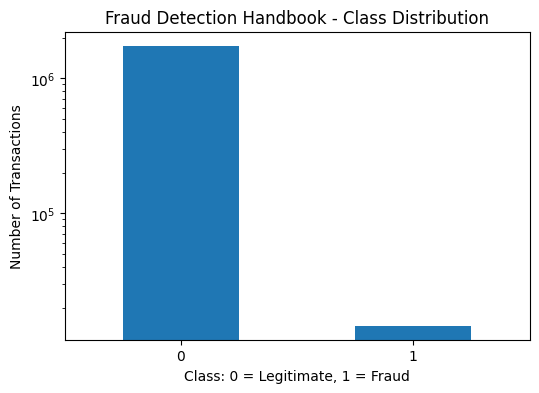

Total transactions: 1,754,155
Fraudulent transactions: 14,681
Fraud percentage: 0.8369%


In [ ]:
# ============================================================
# 5. PRIMARY DATASET CLASS DISTRIBUTION
# ============================================================

class_counts = primary["TX_FRAUD"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")

plt.title("Fraud Detection Handbook - Class Distribution")
plt.xlabel("Class: 0 = Legitimate, 1 = Fraud")
plt.ylabel("Number of Transactions")
plt.yscale("log")
plt.xticks(rotation=0)
plt.show()


fraud_count = int(primary["TX_FRAUD"].sum())
total_count = len(primary)
fraud_percentage = primary["TX_FRAUD"].mean() * 100

print("Total transactions:", f"{total_count:,}")
print("Fraudulent transactions:", f"{fraud_count:,}")
print("Fraud percentage:", f"{fraud_percentage:.4f}%")

<Figure size 700x500 with 0 Axes>

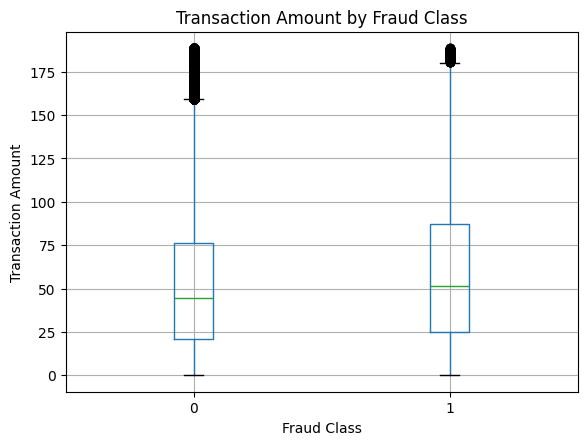

In [ ]:
# ============================================================
# 6. TRANSACTION AMOUNT ANALYSIS
# ============================================================

amount_limit = primary["TX_AMOUNT"].quantile(0.995)

amount_plot = primary[
    primary["TX_AMOUNT"] <= amount_limit
]

plt.figure(figsize=(7, 5))

amount_plot.boxplot(
    column="TX_AMOUNT",
    by="TX_FRAUD"
)

plt.suptitle("")
plt.title("Transaction Amount by Fraud Class")
plt.xlabel("Fraud Class")
plt.ylabel("Transaction Amount")
plt.show()

In [ ]:
# ============================================================
# 7. TEMPORAL FEATURE ENGINEERING
# ============================================================

print("\nCreating temporal features...")


# Weekend indicator

primary["TX_DURING_WEEKEND"] = (
    primary["TX_DATETIME"].dt.weekday >= 5
).astype(int)


# Night-time indicator
# Transactions from midnight through 06:59 are considered night.

primary["TX_DURING_NIGHT"] = (
    primary["TX_DATETIME"].dt.hour <= 6
).astype(int)


print(
    primary[
        [
            "TX_DATETIME",
            "TX_DURING_WEEKEND",
            "TX_DURING_NIGHT"
        ]
    ].head()
)


Creating temporal features...
          TX_DATETIME  TX_DURING_WEEKEND  TX_DURING_NIGHT
0 2018-04-01 00:00:31                  1                1
1 2018-04-01 00:02:10                  1                1
2 2018-04-01 00:07:56                  1                1
3 2018-04-01 00:09:29                  1                1
4 2018-04-01 00:10:34                  1                1


In [ ]:
# ============================================================
# 8. CUSTOMER BEHAVIOURAL FEATURE ENGINEERING
# ============================================================

print("\nCreating customer behavioural features...")
print("This can take several minutes on the complete dataset.")


# Keep the original row position so that the calculated
# rolling features can be returned to the correct transaction.

customer_data = primary[
    [
        "CUSTOMER_ID",
        "TX_DATETIME",
        "TX_AMOUNT"
    ]
].copy()

customer_data["_ROW_ID"] = customer_data.index


# Rolling calculations require transactions to be ordered
# chronologically within each customer.

customer_data = customer_data.sort_values(
    [
        "CUSTOMER_ID",
        "TX_DATETIME",
        "_ROW_ID"
    ]
).reset_index(drop=True)


# ============================================================
# 1-DAY CUSTOMER WINDOW
# ============================================================

customer_roll_1 = (
    customer_data
    .groupby(
        "CUSTOMER_ID",
        sort=False
    )
    .rolling(
        "1D",
        on="TX_DATETIME",
        min_periods=1
    )["TX_AMOUNT"]
    .agg(
        ["count", "mean"]
    )
    .reset_index()
)


# Rolling results follow the same customer/time ordering
# as customer_data.

customer_data[
    "CUSTOMER_ID_NB_TX_1DAY_WINDOW"
] = customer_roll_1[
    "count"
].to_numpy()


customer_data[
    "CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW"
] = customer_roll_1[
    "mean"
].to_numpy()


# ============================================================
# 7-DAY CUSTOMER WINDOW
# ============================================================

customer_roll_7 = (
    customer_data
    .groupby(
        "CUSTOMER_ID",
        sort=False
    )
    .rolling(
        "7D",
        on="TX_DATETIME",
        min_periods=1
    )["TX_AMOUNT"]
    .agg(
        ["count", "mean"]
    )
    .reset_index()
)


customer_data[
    "CUSTOMER_ID_NB_TX_7DAY_WINDOW"
] = customer_roll_7[
    "count"
].to_numpy()


customer_data[
    "CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW"
] = customer_roll_7[
    "mean"
].to_numpy()


# ============================================================
# 30-DAY CUSTOMER WINDOW
# ============================================================

customer_roll_30 = (
    customer_data
    .groupby(
        "CUSTOMER_ID",
        sort=False
    )
    .rolling(
        "30D",
        on="TX_DATETIME",
        min_periods=1
    )["TX_AMOUNT"]
    .agg(
        ["count", "mean"]
    )
    .reset_index()
)


customer_data[
    "CUSTOMER_ID_NB_TX_30DAY_WINDOW"
] = customer_roll_30[
    "count"
].to_numpy()


customer_data[
    "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW"
] = customer_roll_30[
    "mean"
].to_numpy()


# ============================================================
# RESTORE FEATURES TO ORIGINAL TRANSACTION ORDER
# ============================================================

customer_data = customer_data.sort_values(
    "_ROW_ID"
)


primary[
    "CUSTOMER_ID_NB_TX_1DAY_WINDOW"
] = customer_data[
    "CUSTOMER_ID_NB_TX_1DAY_WINDOW"
].to_numpy()


primary[
    "CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW"
] = customer_data[
    "CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW"
].to_numpy()


primary[
    "CUSTOMER_ID_NB_TX_7DAY_WINDOW"
] = customer_data[
    "CUSTOMER_ID_NB_TX_7DAY_WINDOW"
].to_numpy()


primary[
    "CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW"
] = customer_data[
    "CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW"
].to_numpy()


primary[
    "CUSTOMER_ID_NB_TX_30DAY_WINDOW"
] = customer_data[
    "CUSTOMER_ID_NB_TX_30DAY_WINDOW"
].to_numpy()


primary[
    "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW"
] = customer_data[
    "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW"
].to_numpy()


print("\nCustomer behavioural features created successfully.")


print(
    primary[
        [
            "CUSTOMER_ID",
            "TX_DATETIME",
            "TX_AMOUNT",
            "CUSTOMER_ID_NB_TX_1DAY_WINDOW",
            "CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW",
            "CUSTOMER_ID_NB_TX_7DAY_WINDOW",
            "CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW",
            "CUSTOMER_ID_NB_TX_30DAY_WINDOW",
            "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW"
        ]
    ].head(10)
)


# Free unnecessary objects from memory.

del customer_roll_1
del customer_roll_7
del customer_roll_30
del customer_data


Creating customer behavioural features...
This can take several minutes on the complete dataset.

Customer behavioural features created successfully.
  CUSTOMER_ID         TX_DATETIME  TX_AMOUNT  CUSTOMER_ID_NB_TX_1DAY_WINDOW  \
0         596 2018-04-01 00:00:31      57.16                            1.0   
1        4961 2018-04-01 00:02:10      81.51                            1.0   
2           2 2018-04-01 00:07:56     146.00                            1.0   
3        4128 2018-04-01 00:09:29      64.49                            1.0   
4         927 2018-04-01 00:10:34      50.99                            1.0   
5         568 2018-04-01 00:10:45      44.71                            1.0   
6        2803 2018-04-01 00:11:30      96.03                            1.0   
7        4684 2018-04-01 00:11:44      24.36                            1.0   
8        4128 2018-04-01 00:11:53      26.34                            2.0   
9         541 2018-04-01 00:13:44      59.07               

In [ ]:
# ============================================================
# 9. TERMINAL TRANSACTION FREQUENCY FEATURES
# ============================================================

print("\nCreating terminal transaction-frequency features...")


terminal_data = primary[
    [
        "TERMINAL_ID",
        "TX_DATETIME",
        "TX_FRAUD"
    ]
].copy()


# Preserve original transaction position.

terminal_data["_ROW_ID"] = terminal_data.index


# Sort transactions chronologically within each terminal.

terminal_data = terminal_data.sort_values(
    [
        "TERMINAL_ID",
        "TX_DATETIME",
        "_ROW_ID"
    ]
).reset_index(drop=True)


# ============================================================
# 1-DAY TERMINAL TRANSACTION COUNT
# ============================================================

terminal_count_1 = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "1D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .count()
    .reset_index()
)


terminal_data[
    "TERMINAL_ID_NB_TX_1DAY_WINDOW"
] = terminal_count_1[
    "TX_FRAUD"
].fillna(0).to_numpy()


# ============================================================
# 7-DAY TERMINAL TRANSACTION COUNT
# ============================================================

terminal_count_7 = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "7D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .count()
    .reset_index()
)


terminal_data[
    "TERMINAL_ID_NB_TX_7DAY_WINDOW"
] = terminal_count_7[
    "TX_FRAUD"
].fillna(0).to_numpy()


# ============================================================
# 30-DAY TERMINAL TRANSACTION COUNT
# ============================================================

terminal_count_30 = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "30D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .count()
    .reset_index()
)


terminal_data[
    "TERMINAL_ID_NB_TX_30DAY_WINDOW"
] = terminal_count_30[
    "TX_FRAUD"
].fillna(0).to_numpy()


print(
    "\nTerminal transaction-frequency features created."
)


del terminal_count_1
del terminal_count_7
del terminal_count_30


Creating terminal transaction-frequency features...

Terminal transaction-frequency features created.


In [ ]:
# ============================================================
# 10. DELAYED TERMINAL FRAUD-RISK FEATURES
# ============================================================

print("\nCreating delayed terminal fraud-risk features...")

# ------------------------------------------------------------
# IMPORTANT:
#
# A seven-day delay is applied to fraud labels.
#
# For example, when calculating a 30-day terminal fraud-risk
# value, transactions from the most recent seven days are not
# used because their fraud status may not yet have been
# confirmed.
# ------------------------------------------------------------


# ============================================================
# MOST RECENT 7 DAYS
# These fraud labels are excluded from risk calculations.
# ============================================================

recent_7_sum = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "7D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .sum()
    .reset_index()
)


recent_7_count = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "7D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .count()
    .reset_index()
)


recent_7_fraud = (
    recent_7_sum["TX_FRAUD"]
    .fillna(0)
    .to_numpy()
)


recent_7_transactions = (
    recent_7_count["TX_FRAUD"]
    .fillna(0)
    .to_numpy()
)


# ============================================================
# 1-DAY HISTORICAL FRAUD WINDOW
#
# 1-day history + 7-day delay = 8-day total window
# ============================================================

total_8_sum = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "8D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .sum()
    .reset_index()
)


total_8_count = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "8D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .count()
    .reset_index()
)


historical_1_fraud = (
    total_8_sum["TX_FRAUD"]
    .fillna(0)
    .to_numpy()
    -
    recent_7_fraud
)


historical_1_count = (
    total_8_count["TX_FRAUD"]
    .fillna(0)
    .to_numpy()
    -
    recent_7_transactions
)


terminal_data[
    "TERMINAL_ID_RISK_1DAY_WINDOW"
] = np.divide(

    historical_1_fraud,

    historical_1_count,

    out=np.zeros(
        len(terminal_data),
        dtype=float
    ),

    where=historical_1_count > 0
)


# ============================================================
# 7-DAY HISTORICAL FRAUD WINDOW
#
# 7-day history + 7-day delay = 14-day total window
# ============================================================

total_14_sum = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "14D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .sum()
    .reset_index()
)


total_14_count = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "14D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .count()
    .reset_index()
)


historical_7_fraud = (
    total_14_sum["TX_FRAUD"]
    .fillna(0)
    .to_numpy()
    -
    recent_7_fraud
)


historical_7_count = (
    total_14_count["TX_FRAUD"]
    .fillna(0)
    .to_numpy()
    -
    recent_7_transactions
)


terminal_data[
    "TERMINAL_ID_RISK_7DAY_WINDOW"
] = np.divide(

    historical_7_fraud,

    historical_7_count,

    out=np.zeros(
        len(terminal_data),
        dtype=float
    ),

    where=historical_7_count > 0
)


# ============================================================
# 30-DAY HISTORICAL FRAUD WINDOW
#
# 30-day history + 7-day delay = 37-day total window
# ============================================================

total_37_sum = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "37D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .sum()
    .reset_index()
)


total_37_count = (
    terminal_data
    .groupby(
        "TERMINAL_ID",
        sort=False
    )
    .rolling(
        "37D",
        on="TX_DATETIME",
        closed="left"
    )["TX_FRAUD"]
    .count()
    .reset_index()
)


historical_30_fraud = (
    total_37_sum["TX_FRAUD"]
    .fillna(0)
    .to_numpy()
    -
    recent_7_fraud
)


historical_30_count = (
    total_37_count["TX_FRAUD"]
    .fillna(0)
    .to_numpy()
    -
    recent_7_transactions
)


terminal_data[
    "TERMINAL_ID_RISK_30DAY_WINDOW"
] = np.divide(

    historical_30_fraud,

    historical_30_count,

    out=np.zeros(
        len(terminal_data),
        dtype=float
    ),

    where=historical_30_count > 0
)


# ============================================================
# RESTORE TERMINAL FEATURES TO ORIGINAL TRANSACTION ORDER
# ============================================================

terminal_data = terminal_data.sort_values(
    "_ROW_ID"
)


primary[
    "TERMINAL_ID_NB_TX_1DAY_WINDOW"
] = terminal_data[
    "TERMINAL_ID_NB_TX_1DAY_WINDOW"
].to_numpy()


primary[
    "TERMINAL_ID_RISK_1DAY_WINDOW"
] = terminal_data[
    "TERMINAL_ID_RISK_1DAY_WINDOW"
].to_numpy()


primary[
    "TERMINAL_ID_NB_TX_7DAY_WINDOW"
] = terminal_data[
    "TERMINAL_ID_NB_TX_7DAY_WINDOW"
].to_numpy()


primary[
    "TERMINAL_ID_RISK_7DAY_WINDOW"
] = terminal_data[
    "TERMINAL_ID_RISK_7DAY_WINDOW"
].to_numpy()


primary[
    "TERMINAL_ID_NB_TX_30DAY_WINDOW"
] = terminal_data[
    "TERMINAL_ID_NB_TX_30DAY_WINDOW"
].to_numpy()


primary[
    "TERMINAL_ID_RISK_30DAY_WINDOW"
] = terminal_data[
    "TERMINAL_ID_RISK_30DAY_WINDOW"
].to_numpy()


print(
    "\nDelayed terminal fraud-risk features created successfully."
)


print(
    primary[
        [
            "TERMINAL_ID",
            "TX_DATETIME",
            "TERMINAL_ID_NB_TX_1DAY_WINDOW",
            "TERMINAL_ID_RISK_1DAY_WINDOW",
            "TERMINAL_ID_NB_TX_7DAY_WINDOW",
            "TERMINAL_ID_RISK_7DAY_WINDOW",
            "TERMINAL_ID_NB_TX_30DAY_WINDOW",
            "TERMINAL_ID_RISK_30DAY_WINDOW"
        ]
    ].head(10)
)


# ============================================================
# REMOVE TEMPORARY VARIABLES
# ============================================================

del recent_7_sum
del recent_7_count
del recent_7_fraud
del recent_7_transactions

del total_8_sum
del total_8_count
del historical_1_fraud
del historical_1_count

del total_14_sum
del total_14_count
del historical_7_fraud
del historical_7_count

del total_37_sum
del total_37_count
del historical_30_fraud
del historical_30_count

del terminal_data


Creating delayed terminal fraud-risk features...

Delayed terminal fraud-risk features created successfully.
  TERMINAL_ID         TX_DATETIME  TERMINAL_ID_NB_TX_1DAY_WINDOW  \
0        3156 2018-04-01 00:00:31                            0.0   
1        3412 2018-04-01 00:02:10                            0.0   
2        1365 2018-04-01 00:07:56                            0.0   
3        8737 2018-04-01 00:09:29                            0.0   
4        9906 2018-04-01 00:10:34                            0.0   
5        8803 2018-04-01 00:10:45                            0.0   
6        5490 2018-04-01 00:11:30                            0.0   
7        2486 2018-04-01 00:11:44                            0.0   
8        8354 2018-04-01 00:11:53                            0.0   
9        6212 2018-04-01 00:13:44                            0.0   

   TERMINAL_ID_RISK_1DAY_WINDOW  TERMINAL_ID_NB_TX_7DAY_WINDOW  \
0                           0.0                            0.0   
1        

In [ ]:
# ============================================================
# 11. FINAL PRIMARY DATASET FEATURES
# ============================================================

PRIMARY_FEATURES = [

    "TX_AMOUNT",

    "TX_DURING_WEEKEND",
    "TX_DURING_NIGHT",

    "CUSTOMER_ID_NB_TX_1DAY_WINDOW",
    "CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW",

    "CUSTOMER_ID_NB_TX_7DAY_WINDOW",
    "CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW",

    "CUSTOMER_ID_NB_TX_30DAY_WINDOW",
    "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW",

    "TERMINAL_ID_NB_TX_1DAY_WINDOW",
    "TERMINAL_ID_RISK_1DAY_WINDOW",

    "TERMINAL_ID_NB_TX_7DAY_WINDOW",
    "TERMINAL_ID_RISK_7DAY_WINDOW",

    "TERMINAL_ID_NB_TX_30DAY_WINDOW",
    "TERMINAL_ID_RISK_30DAY_WINDOW"
]


print("\nNumber of primary predictors:")
print(len(PRIMARY_FEATURES))

print("\nPrimary predictors:")
for feature in PRIMARY_FEATURES:
    print(feature)


print("\nMissing values in engineered predictors:")
print(primary[PRIMARY_FEATURES].isnull().sum())


# Any unexpected missing engineered values are replaced
# with zero where no history exists.

primary[PRIMARY_FEATURES] = (
    primary[PRIMARY_FEATURES]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)


print("\nDescriptive statistics:")
display(
    primary[PRIMARY_FEATURES]
    .describe()
    .T
)


Number of primary predictors:
15

Primary predictors:
TX_AMOUNT
TX_DURING_WEEKEND
TX_DURING_NIGHT
CUSTOMER_ID_NB_TX_1DAY_WINDOW
CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW
CUSTOMER_ID_NB_TX_7DAY_WINDOW
CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW
CUSTOMER_ID_NB_TX_30DAY_WINDOW
CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW
TERMINAL_ID_NB_TX_1DAY_WINDOW
TERMINAL_ID_RISK_1DAY_WINDOW
TERMINAL_ID_NB_TX_7DAY_WINDOW
TERMINAL_ID_RISK_7DAY_WINDOW
TERMINAL_ID_NB_TX_30DAY_WINDOW
TERMINAL_ID_RISK_30DAY_WINDOW

Missing values in engineered predictors:
TX_AMOUNT                              0
TX_DURING_WEEKEND                      0
TX_DURING_NIGHT                        0
CUSTOMER_ID_NB_TX_1DAY_WINDOW          0
CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW     0
CUSTOMER_ID_NB_TX_7DAY_WINDOW          0
CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW     0
CUSTOMER_ID_NB_TX_30DAY_WINDOW         0
CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW    0
TERMINAL_ID_NB_TX_1DAY_WINDOW          0
TERMINAL_ID_RISK_1DAY_WINDOW           0
TERMINAL_ID_NB_TX_7DAY_WINDOW   

,count,mean,std,min,25%,50%,75%,max
TX_AMOUNT,1754155.0,53.632302,42.326492,0.00,21.010000,44.640000,76.950000,2628.000000
TX_DURING_WEEKEND,1754155.0,0.289818,0.453678,0.00,0.000000,0.000000,1.000000,1.000000
TX_DURING_NIGHT,1754155.0,0.173855,0.378985,0.00,0.000000,0.000000,0.000000,1.000000
CUSTOMER_ID_NB_TX_1DAY_WINDOW,1754155.0,3.560578,1.847658,1.00,2.000000,3.000000,5.000000,16.000000
CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,1754155.0,53.627445,35.046348,0.00,25.710000,49.253333,76.000000,1377.075000
CUSTOMER_ID_NB_TX_7DAY_WINDOW,1754155.0,18.640448,7.883447,1.00,13.000000,19.000000,24.000000,52.000000
CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,1754155.0,53.615081,30.467939,0.02,28.246000,52.364500,76.881188,509.283333
CUSTOMER_ID_NB_TX_30DAY_WINDOW,1754155.0,71.749396,32.167901,1.00,47.000000,76.000000,98.000000,157.000000
CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,1754155.0,53.602783,29.339725,0.21,28.678939,53.026429,77.608783,291.090000
TERMINAL_ID_NB_TX_1DAY_WINDOW,1754155.0,0.998050,1.022056,0.00,0.000000,1.000000,2.000000,11.000000


In [ ]:
# ============================================================
# 12. VERIFY VARIABLES EXCLUDED TO PREVENT LEAKAGE
# ============================================================

print("\nVariables excluded from prediction:")

print("TRANSACTION_ID")
print("CUSTOMER_ID")
print("TERMINAL_ID")
print("TX_FRAUD_SCENARIO")
print("TX_FRAUD - target variable")


assert "TRANSACTION_ID" not in PRIMARY_FEATURES
assert "CUSTOMER_ID" not in PRIMARY_FEATURES
assert "TERMINAL_ID" not in PRIMARY_FEATURES
assert "TX_FRAUD_SCENARIO" not in PRIMARY_FEATURES
assert "TX_FRAUD" not in PRIMARY_FEATURES


Variables excluded from prediction:
TRANSACTION_ID
CUSTOMER_ID
TERMINAL_ID
TX_FRAUD_SCENARIO
TX_FRAUD - target variable


In [ ]:
# ============================================================
# 13. CHRONOLOGICAL PRIMARY TRAIN / VALIDATION / TEST SPLIT
# ============================================================

print("\n" + "=" * 70)
print("PRIMARY DATASET CHRONOLOGICAL SPLIT")
print("=" * 70)


primary["DATE"] = (
    primary["TX_DATETIME"]
    .dt.normalize()
)

unique_dates = np.array(
    sorted(
        primary["DATE"].unique()
    )
)

number_of_days = len(unique_dates)

train_end = int(
    number_of_days * 0.60
)

validation_end = int(
    number_of_days * 0.80
)

train_dates = unique_dates[:train_end]

validation_dates = unique_dates[
    train_end:validation_end
]

test_dates = unique_dates[
    validation_end:
]


primary_train = primary[
    primary["DATE"].isin(train_dates)
].copy()

primary_validation = primary[
    primary["DATE"].isin(validation_dates)
].copy()

primary_test = primary[
    primary["DATE"].isin(test_dates)
].copy()


print("\nTraining data:")
print("Rows:", len(primary_train))
print(
    "Period:",
    primary_train["TX_DATETIME"].min(),
    "to",
    primary_train["TX_DATETIME"].max()
)
print(
    "Fraud rate:",
    f"{primary_train['TX_FRAUD'].mean()*100:.4f}%"
)


print("\nValidation data:")
print("Rows:", len(primary_validation))
print(
    "Period:",
    primary_validation["TX_DATETIME"].min(),
    "to",
    primary_validation["TX_DATETIME"].max()
)
print(
    "Fraud rate:",
    f"{primary_validation['TX_FRAUD'].mean()*100:.4f}%"
)


print("\nTest data:")
print("Rows:", len(primary_test))
print(
    "Period:",
    primary_test["TX_DATETIME"].min(),
    "to",
    primary_test["TX_DATETIME"].max()
)
print(
    "Fraud rate:",
    f"{primary_test['TX_FRAUD'].mean()*100:.4f}%"
)


PRIMARY DATASET CHRONOLOGICAL SPLIT

Training data:
Rows: 1045189
Period: 2018-04-01 00:00:31 to 2018-07-18 23:58:32
Fraud rate: 0.8057%

Validation data:
Rows: 354323
Period: 2018-07-19 00:01:24 to 2018-08-24 23:59:37
Fraud rate: 0.8701%

Test data:
Rows: 354643
Period: 2018-08-25 00:00:23 to 2018-09-30 23:59:57
Fraud rate: 0.8958%


In [ ]:
# ============================================================
# 14. TRADITIONAL RULE-BASED FRAUD BASELINE
# ============================================================

print("\n" + "=" * 70)
print("TRADITIONAL RULE-BASED FRAUD BASELINE")
print("=" * 70)


# Thresholds are calculated from TRAINING DATA ONLY.

high_amount_threshold = (
    primary_train["TX_AMOUNT"]
    .quantile(0.99)
)

high_frequency_threshold = (
    primary_train[
        "CUSTOMER_ID_NB_TX_1DAY_WINDOW"
    ]
    .quantile(0.99)
)

terminal_risk_threshold = (
    primary_train[
        "TERMINAL_ID_RISK_30DAY_WINDOW"
    ]
    .quantile(0.99)
)


print("High transaction threshold:", high_amount_threshold)
print("High frequency threshold:", high_frequency_threshold)
print("Terminal risk threshold:", terminal_risk_threshold)


TRADITIONAL RULE-BASED FRAUD BASELINE
High transaction threshold: 171.34
High frequency threshold: 9.0
Terminal risk threshold: 0.07692307692307693


In [ ]:
# ---------------------------
# Validation rule score
# ---------------------------

validation_rule_score = np.zeros(
    len(primary_validation)
)


validation_rule_score += (
    primary_validation["TX_AMOUNT"]
    > high_amount_threshold
).astype(int).values


validation_rule_score += (
    primary_validation["TX_AMOUNT"]
    >
    2 *
    primary_validation[
        "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW"
    ]
).astype(int).values


validation_rule_score += (
    primary_validation[
        "CUSTOMER_ID_NB_TX_1DAY_WINDOW"
    ]
    > high_frequency_threshold
).astype(int).values


validation_rule_score += (
    primary_validation[
        "TX_DURING_NIGHT"
    ] == 1
).astype(int).values


if terminal_risk_threshold > 0:

    validation_rule_score += (
        primary_validation[
            "TERMINAL_ID_RISK_30DAY_WINDOW"
        ]
        > terminal_risk_threshold
    ).astype(int).values

else:

    validation_rule_score += (
        primary_validation[
            "TERMINAL_ID_RISK_30DAY_WINDOW"
        ]
        > 0
    ).astype(int).values


# Select the number of rules that gives the best F1 on validation data.

rule_validation_results = []

for rule_threshold in [1, 2, 3, 4, 5]:

    validation_prediction = (
        validation_rule_score >= rule_threshold
    ).astype(int)

    p = precision_score(
        primary_validation["TX_FRAUD"],
        validation_prediction,
        zero_division=0
    )

    r = recall_score(
        primary_validation["TX_FRAUD"],
        validation_prediction,
        zero_division=0
    )

    f = f1_score(
        primary_validation["TX_FRAUD"],
        validation_prediction,
        zero_division=0
    )

    rule_validation_results.append(
        {
            "Rule Threshold": rule_threshold,
            "Precision": p,
            "Recall": r,
            "F1": f
        }
    )


rule_validation_table = pd.DataFrame(
    rule_validation_results
)

display(rule_validation_table)


best_rule_threshold = int(
    rule_validation_table
    .sort_values(
        "F1",
        ascending=False
    )
    .iloc[0]["Rule Threshold"]
)


print(
    "Selected rule threshold:",
    best_rule_threshold
)

,Rule Threshold,Precision,Recall,F1
0,1,0.033402,0.795654,0.064112
1,2,0.251320,0.339604,0.288867
2,3,0.382979,0.040869,0.073857
3,4,0.200000,0.000324,0.000648
4,5,0.000000,0.000000,0.000000


Selected rule threshold: 2



Traditional rule-based test results:


,Dataset,Model,Strategy,PR_AUC,Precision,Recall,F1,ROC_AUC,Specificity,False_Positive_Rate,Balanced_Accuracy,MCC,Accuracy
0,Fraud Detection Handbook,Traditional Rule-Based,Rules,0.108541,0.252677,0.334278,0.287805,0.821772,0.991063,0.008937,0.66267,0.283271,0.985179


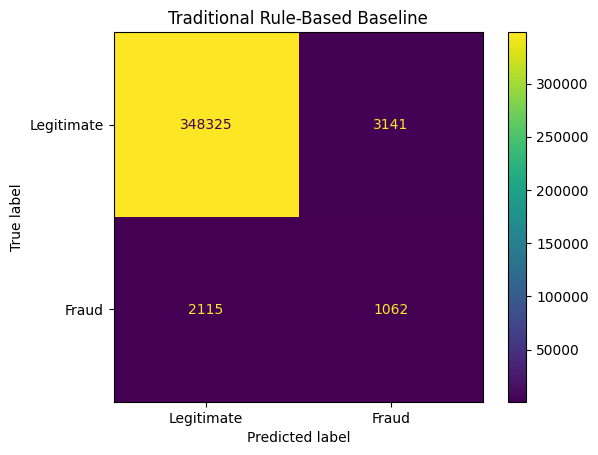

In [ ]:
# ---------------------------
# Test rule score
# ---------------------------

test_rule_score = np.zeros(
    len(primary_test)
)


test_rule_score += (
    primary_test["TX_AMOUNT"]
    > high_amount_threshold
).astype(int).values


test_rule_score += (
    primary_test["TX_AMOUNT"]
    >
    2 *
    primary_test[
        "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW"
    ]
).astype(int).values


test_rule_score += (
    primary_test[
        "CUSTOMER_ID_NB_TX_1DAY_WINDOW"
    ]
    > high_frequency_threshold
).astype(int).values


test_rule_score += (
    primary_test[
        "TX_DURING_NIGHT"
    ] == 1
).astype(int).values


if terminal_risk_threshold > 0:

    test_rule_score += (
        primary_test[
            "TERMINAL_ID_RISK_30DAY_WINDOW"
        ]
        > terminal_risk_threshold
    ).astype(int).values

else:

    test_rule_score += (
        primary_test[
            "TERMINAL_ID_RISK_30DAY_WINDOW"
        ]
        > 0
    ).astype(int).values


rule_test_prediction = (
    test_rule_score >= best_rule_threshold
).astype(int)


rule_probability = (
    test_rule_score / 5
)


rule_tn, rule_fp, rule_fn, rule_tp = (
    confusion_matrix(
        primary_test["TX_FRAUD"],
        rule_test_prediction
    ).ravel()
)


rule_specificity = (
    rule_tn /
    (rule_tn + rule_fp)
)

rule_fpr = (
    rule_fp /
    (rule_fp + rule_tn)
)


rule_results = pd.DataFrame(
    [
        {
            "Dataset":
                "Fraud Detection Handbook",

            "Model":
                "Traditional Rule-Based",

            "Strategy":
                "Rules",

            "PR_AUC":
                average_precision_score(
                    primary_test["TX_FRAUD"],
                    rule_probability
                ),

            "Precision":
                precision_score(
                    primary_test["TX_FRAUD"],
                    rule_test_prediction,
                    zero_division=0
                ),

            "Recall":
                recall_score(
                    primary_test["TX_FRAUD"],
                    rule_test_prediction,
                    zero_division=0
                ),

            "F1":
                f1_score(
                    primary_test["TX_FRAUD"],
                    rule_test_prediction,
                    zero_division=0
                ),

            "ROC_AUC":
                roc_auc_score(
                    primary_test["TX_FRAUD"],
                    rule_probability
                ),

            "Specificity":
                rule_specificity,

            "False_Positive_Rate":
                rule_fpr,

            "Balanced_Accuracy":
                balanced_accuracy_score(
                    primary_test["TX_FRAUD"],
                    rule_test_prediction
                ),

            "MCC":
                matthews_corrcoef(
                    primary_test["TX_FRAUD"],
                    rule_test_prediction
                ),

            "Accuracy":
                accuracy_score(
                    primary_test["TX_FRAUD"],
                    rule_test_prediction
                )
        }
    ]
)


print("\nTraditional rule-based test results:")
display(rule_results)


ConfusionMatrixDisplay.from_predictions(
    primary_test["TX_FRAUD"],
    rule_test_prediction,
    display_labels=[
        "Legitimate",
        "Fraud"
    ]
)

plt.title(
    "Traditional Rule-Based Baseline"
)
plt.show()

In [ ]:
# ============================================================
# 15. LOAD ULB EUROPEAN CREDIT CARD FRAUD DATASET
# ============================================================

print("\n" + "=" * 70)
print("LOADING ULB EUROPEAN CREDIT CARD FRAUD DATASET")
print("=" * 70)


if not ULB_PATH.exists():

    raise FileNotFoundError(
        f"ULB dataset was not found:\n{ULB_PATH}"
    )


rdata_result = pyreadr.read_r(
    str(ULB_PATH)
)


print(
    "Objects inside the RData file:",
    list(rdata_result.keys())
)


# The Kaggle file contains a data frame.
# Select the first data frame.

ulb = list(
    rdata_result.values()
)[0].copy()


# Standardise column names

ulb.columns = [
    str(column).strip()
    for column in ulb.columns
]


rename_columns = {}

for column in ulb.columns:

    if column.lower() == "time":
        rename_columns[column] = "Time"

    elif column.lower() == "amount":
        rename_columns[column] = "Amount"

    elif column.lower() == "class":
        rename_columns[column] = "Class"

    elif (
        column.lower().startswith("v")
        and column[1:].isdigit()
    ):
        rename_columns[column] = (
            "V" + column[1:]
        )


ulb = ulb.rename(
    columns=rename_columns
)


ULB_FEATURES = (
    ["Time"]
    +
    [f"V{i}" for i in range(1, 29)]
    +
    ["Amount"]
)


expected_ulb_columns = (
    ULB_FEATURES
    +
    ["Class"]
)


missing_columns = [
    column
    for column in expected_ulb_columns
    if column not in ulb.columns
]


if len(missing_columns) > 0:

    print(
        "Columns found:",
        ulb.columns.tolist()
    )

    raise ValueError(
        f"Missing expected ULB columns: "
        f"{missing_columns}"
    )


ulb = ulb[
    expected_ulb_columns
].copy()


# Convert variables to numeric

for column in ULB_FEATURES:

    ulb[column] = pd.to_numeric(
        ulb[column],
        errors="coerce"
    )


ulb["Class"] = pd.to_numeric(
    ulb["Class"],
    errors="coerce"
)


print("\nULB dataset loaded successfully.")
print("Shape:", ulb.shape)

display(ulb.head())


LOADING ULB EUROPEAN CREDIT CARD FRAUD DATASET
Objects inside the RData file: ['creditcard']

ULB dataset loaded successfully.
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
rownames,,,,,,,,,,,,,,,,,,,,,
1,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
2,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
3,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
4,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
5,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
# ============================================================
# 16. ULB DATASET VALIDATION AND CLEANING
# ============================================================

print("\n" + "=" * 70)
print("ULB DATA VALIDATION")
print("=" * 70)


print("\nMissing values:")
print(ulb.isnull().sum())

print("\nTotal missing values:")
print(ulb.isnull().sum().sum())

print("\nExact duplicated rows:")
print(ulb.duplicated().sum())

print("\nNegative transaction amounts:")
print((ulb["Amount"] < 0).sum())


# Remove rows with missing essential values.

ulb = ulb.dropna(
    subset=expected_ulb_columns
).copy()


# Remove impossible negative transaction amounts.

ulb = ulb[
    ulb["Amount"] >= 0
].copy()


ulb["Class"] = (
    ulb["Class"]
    .astype(int)
)


valid_ulb_targets = set(
    ulb["Class"].unique()
)

if not valid_ulb_targets.issubset(
    {0, 1}
):

    raise ValueError(
        "Unexpected values in Class."
    )


# Do not automatically delete ULB duplicate feature rows.
# The anonymised dataset has no transaction identifier,
# so identical observations cannot confidently be established
# as accidental duplicates.


print("\nClean ULB shape:")
print(ulb.shape)


print("\nClass distribution:")
print(
    ulb["Class"]
    .value_counts()
)


print("\nClass percentage:")
print(
    ulb["Class"]
    .value_counts(normalize=True)
    .mul(100)
)


print(
    "\nFraud percentage:",
    f"{ulb['Class'].mean()*100:.4f}%"
)


ULB DATA VALIDATION

Missing values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Total missing values:
0

Exact duplicated rows:
1081

Negative transaction amounts:
0

Clean ULB shape:
(284807, 31)

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Fraud percentage: 0.1727%


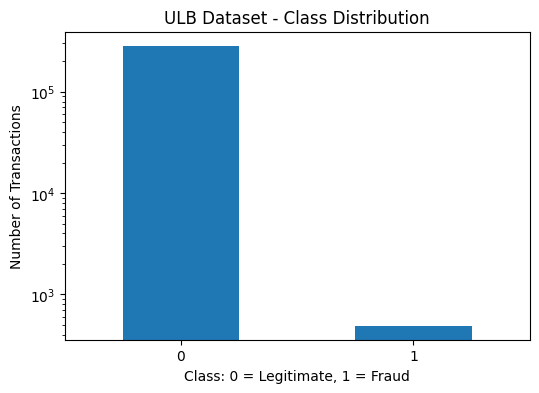

In [ ]:
# ============================================================
# 17. ULB CLASS DISTRIBUTION
# ============================================================

ulb_class_counts = (
    ulb["Class"]
    .value_counts()
    .sort_index()
)


plt.figure(figsize=(6, 4))

ulb_class_counts.plot(
    kind="bar"
)

plt.title(
    "ULB Dataset - Class Distribution"
)

plt.xlabel(
    "Class: 0 = Legitimate, 1 = Fraud"
)

plt.ylabel(
    "Number of Transactions"
)

plt.yscale("log")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# ============================================================
# 18. ULB STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

ulb_train_validation, ulb_test = (
    train_test_split(
        ulb,
        test_size=0.20,
        stratify=ulb["Class"],
        random_state=RANDOM_STATE
    )
)


ulb_train, ulb_validation = (
    train_test_split(
        ulb_train_validation,
        test_size=0.25,
        stratify=(
            ulb_train_validation["Class"]
        ),
        random_state=RANDOM_STATE
    )
)


print("\nULB Training:")
print("Rows:", len(ulb_train))
print(
    "Fraud rate:",
    f"{ulb_train['Class'].mean()*100:.4f}%"
)


print("\nULB Validation:")
print("Rows:", len(ulb_validation))
print(
    "Fraud rate:",
    f"{ulb_validation['Class'].mean()*100:.4f}%"
)


print("\nULB Test:")
print("Rows:", len(ulb_test))
print(
    "Fraud rate:",
    f"{ulb_test['Class'].mean()*100:.4f}%"
)


ULB Training:
Rows: 170883
Fraud rate: 0.1726%

ULB Validation:
Rows: 56962
Fraud rate: 0.1738%

ULB Test:
Rows: 56962
Fraud rate: 0.1720%


In [ ]:
# ============================================================
# 19. PREPARE BOTH DATASETS FOR MACHINE LEARNING
# ============================================================

datasets = []


datasets.append(
    {
        "name":
            "Fraud Detection Handbook",

        "features":
            PRIMARY_FEATURES,

        "target":
            "TX_FRAUD",

        "train":
            primary_train,

        "validation":
            primary_validation,

        "test":
            primary_test
    }
)


datasets.append(
    {
        "name":
            "ULB",

        "features":
            ULB_FEATURES,

        "target":
            "Class",

        "train":
            ulb_train,

        "validation":
            ulb_validation,

        "test":
            ulb_test
    }
)

In [ ]:
# ============================================================
# 20. MACHINE LEARNING EXPERIMENTS
# ============================================================

print("\n" + "=" * 70)
print("MACHINE LEARNING MODEL DEVELOPMENT")
print("=" * 70)


all_model_results = []

best_model_per_algorithm = {}

best_overall_model = {}
best_overall_probability = {}
best_overall_information = {}


strategies = [
    "Original",
    "Class Weight",
    "SMOTE"
]


models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "XGBoost"
]


for dataset_information in datasets:

    dataset_name = dataset_information["name"]
    feature_columns = dataset_information["features"]
    target_column = dataset_information["target"]

    train_data = dataset_information["train"]
    validation_data = dataset_information["validation"]
    test_data = dataset_information["test"]


    print(
        "\n\n" + "=" * 70
    )

    print(
        "DATASET:",
        dataset_name
    )

    print(
        "=" * 70
    )


    X_train = train_data[
        feature_columns
    ].copy()

    y_train = train_data[
        target_column
    ].astype(int).copy()


    X_validation = validation_data[
        feature_columns
    ].copy()

    y_validation = validation_data[
        target_column
    ].astype(int).copy()


    X_test = test_data[
        feature_columns
    ].copy()

    y_test = test_data[
        target_column
    ].astype(int).copy()


    # --------------------------------------------------------
    # Combined training + validation data is used by
    # PredefinedSplit during hyperparameter selection.
    # --------------------------------------------------------

    X_train_validation = pd.concat(
        [
            X_train,
            X_validation
        ],
        ignore_index=True
    )


    y_train_validation = pd.concat(
        [
            y_train,
            y_validation
        ],
        ignore_index=True
    )


    # -1 means training observation
    # 0 means validation observation

    validation_fold = np.concatenate(
        [
            np.full(
                len(X_train),
                -1
            ),

            np.zeros(
                len(X_validation),
                dtype=int
            )
        ]
    )


    predefined_split = PredefinedSplit(
        validation_fold
    )


    # Ratio used by weighted XGBoost

    number_legitimate = (
        y_train == 0
    ).sum()

    number_fraud = (
        y_train == 1
    ).sum()

    positive_weight = (
        number_legitimate
        /
        number_fraud
    )


    for model_name in models:

        for strategy in strategies:

            print(
                "\n" + "-" * 65
            )

            print(
                dataset_name,
                "|",
                model_name,
                "|",
                strategy
            )

            print(
                "-" * 65
            )


            # =================================================
            # LOGISTIC REGRESSION
            # =================================================

            if model_name == "Logistic Regression":

                if strategy == "Class Weight":

                    estimator = LogisticRegression(
                        max_iter=2000,
                        class_weight="balanced",
                        random_state=RANDOM_STATE
                    )

                else:

                    estimator = LogisticRegression(
                        max_iter=2000,
                        class_weight=None,
                        random_state=RANDOM_STATE
                    )


                pipeline_steps = [

                    (
                        "imputer",
                        SimpleImputer(
                            strategy="median"
                        )
                    ),

                    (
                        "scaler",
                        StandardScaler()
                    )
                ]


                if strategy == "SMOTE":

                    pipeline_steps.append(
                        (
                            "smote",
                            SMOTE(
                                sampling_strategy=0.10,
                                random_state=RANDOM_STATE
                            )
                        )
                    )


                pipeline_steps.append(
                    (
                        "model",
                        estimator
                    )
                )


                pipeline = ImbPipeline(
                    pipeline_steps
                )


                parameter_grid = {
                    "model__C":
                        [
                            0.1,
                            1,
                            10
                        ]
                }


            # =================================================
            # DECISION TREE
            # =================================================

            elif model_name == "Decision Tree":

                if strategy == "Class Weight":

                    estimator = DecisionTreeClassifier(
                        class_weight="balanced",
                        random_state=RANDOM_STATE
                    )

                else:

                    estimator = DecisionTreeClassifier(
                        random_state=RANDOM_STATE
                    )


                pipeline_steps = [

                    (
                        "imputer",
                        SimpleImputer(
                            strategy="median"
                        )
                    )
                ]


                if strategy == "SMOTE":

                    pipeline_steps.append(
                        (
                            "smote",
                            SMOTE(
                                sampling_strategy=0.10,
                                random_state=RANDOM_STATE
                            )
                        )
                    )


                pipeline_steps.append(
                    (
                        "model",
                        estimator
                    )
                )


                pipeline = ImbPipeline(
                    pipeline_steps
                )


                parameter_grid = {

                    "model__max_depth":
                        [
                            5,
                            10,
                            15
                        ],

                    "model__min_samples_leaf":
                        [
                            20,
                            100
                        ]
                }


            # =================================================
            # RANDOM FOREST
            # =================================================

            elif model_name == "Random Forest":

                if strategy == "Class Weight":

                    estimator = RandomForestClassifier(
                        n_estimators=100,
                        class_weight="balanced",
                        random_state=RANDOM_STATE,
                        n_jobs=-1
                    )

                else:

                    estimator = RandomForestClassifier(
                        n_estimators=100,
                        random_state=RANDOM_STATE,
                        n_jobs=-1
                    )


                pipeline_steps = [

                    (
                        "imputer",
                        SimpleImputer(
                            strategy="median"
                        )
                    )
                ]


                if strategy == "SMOTE":

                    pipeline_steps.append(
                        (
                            "smote",
                            SMOTE(
                                sampling_strategy=0.10,
                                random_state=RANDOM_STATE
                            )
                        )
                    )


                pipeline_steps.append(
                    (
                        "model",
                        estimator
                    )
                )


                pipeline = ImbPipeline(
                    pipeline_steps
                )


                parameter_grid = {

                    "model__max_depth":
                        [
                            10,
                            20
                        ],

                    "model__max_features":
                        [
                            "sqrt",
                            0.7
                        ]
                }


            # =================================================
            # XGBOOST
            # =================================================

            else:

                if strategy == "Class Weight":

                    xgb_weight = (
                        positive_weight
                    )

                else:

                    xgb_weight = 1


                estimator = XGBClassifier(

                    n_estimators=150,

                    objective=
                        "binary:logistic",

                    eval_metric=
                        "logloss",

                    tree_method=
                        "hist",

                    scale_pos_weight=
                        xgb_weight,

                    random_state=
                        RANDOM_STATE,

                    n_jobs=-1
                )


                pipeline_steps = [

                    (
                        "imputer",
                        SimpleImputer(
                            strategy="median"
                        )
                    )
                ]


                if strategy == "SMOTE":

                    pipeline_steps.append(
                        (
                            "smote",
                            SMOTE(
                                sampling_strategy=0.10,
                                random_state=RANDOM_STATE
                            )
                        )
                    )


                pipeline_steps.append(
                    (
                        "model",
                        estimator
                    )
                )


                pipeline = ImbPipeline(
                    pipeline_steps
                )


                parameter_grid = {

                    "model__max_depth":
                        [
                            3,
                            5
                        ],

                    "model__learning_rate":
                        [
                            0.05,
                            0.10
                        ]
                }


            # =================================================
            # HYPERPARAMETER TUNING
            # =================================================

            search = GridSearchCV(

                estimator=pipeline,

                param_grid=
                    parameter_grid,

                scoring=
                    "average_precision",

                cv=
                    predefined_split,

                refit=False,

                n_jobs=1,

                verbose=0
            )


            start_time = time.time()


            search.fit(
                X_train_validation,
                y_train_validation
            )


            tuning_time = (
                time.time()
                -
                start_time
            )


            print(
                "Best parameters:",
                search.best_params_
            )

            print(
                "Validation PR-AUC:",
                round(
                    search.best_score_,
                    4
                )
            )


            # =================================================
            # VALIDATION MODEL FOR THRESHOLD SELECTION
            # =================================================

            validation_model = clone(
                pipeline
            )

            validation_model.set_params(
                **search.best_params_
            )


            validation_model.fit(
                X_train,
                y_train
            )


            validation_probability = (
                validation_model
                .predict_proba(
                    X_validation
                )[:, 1]
            )


            validation_precision, \
            validation_recall, \
            validation_thresholds = (
                precision_recall_curve(
                    y_validation,
                    validation_probability
                )
            )


            validation_f1_scores = (

                2
                *
                validation_precision[:-1]
                *
                validation_recall[:-1]

                /

                (
                    validation_precision[:-1]
                    +
                    validation_recall[:-1]
                    +
                    1e-10
                )
            )


            best_threshold_index = (
                np.argmax(
                    validation_f1_scores
                )
            )


            selected_threshold = (
                validation_thresholds[
                    best_threshold_index
                ]
            )


            print(
                "Selected probability threshold:",
                round(
                    selected_threshold,
                    4
                )
            )


            # =================================================
            # FINAL MODEL
            # TRAIN + VALIDATION
            # =================================================

            final_model = clone(
                pipeline
            )

            final_model.set_params(
                **search.best_params_
            )


            final_training_start = (
                time.time()
            )


            final_model.fit(
                X_train_validation,
                y_train_validation
            )


            training_time = (
                time.time()
                -
                final_training_start
            )


            prediction_start = (
                time.time()
            )


            test_probability = (
                final_model
                .predict_proba(
                    X_test
                )[:, 1]
            )


            prediction_time = (
                time.time()
                -
                prediction_start
            )


            test_prediction = (
                test_probability
                >=
                selected_threshold
            ).astype(int)


            # =================================================
            # TEST PERFORMANCE
            # =================================================

            tn, fp, fn, tp = (
                confusion_matrix(
                    y_test,
                    test_prediction
                ).ravel()
            )


            specificity = (
                tn
                /
                (tn + fp)
            )


            false_positive_rate = (
                fp
                /
                (fp + tn)
            )


            pr_auc = (
                average_precision_score(
                    y_test,
                    test_probability
                )
            )


            roc_auc = (
                roc_auc_score(
                    y_test,
                    test_probability
                )
            )


            test_precision_value = (
                precision_score(
                    y_test,
                    test_prediction,
                    zero_division=0
                )
            )


            test_recall_value = (
                recall_score(
                    y_test,
                    test_prediction,
                    zero_division=0
                )
            )


            test_f1_value = (
                f1_score(
                    y_test,
                    test_prediction,
                    zero_division=0
                )
            )


            balanced_accuracy_value = (
                balanced_accuracy_score(
                    y_test,
                    test_prediction
                )
            )


            mcc_value = (
                matthews_corrcoef(
                    y_test,
                    test_prediction
                )
            )


            accuracy_value = (
                accuracy_score(
                    y_test,
                    test_prediction
                )
            )


            print(
                "\nTest PR-AUC:",
                round(pr_auc, 4)
            )

            print(
                "Precision:",
                round(
                    test_precision_value,
                    4
                )
            )

            print(
                "Recall:",
                round(
                    test_recall_value,
                    4
                )
            )

            print(
                "F1:",
                round(
                    test_f1_value,
                    4
                )
            )

            print(
                "ROC-AUC:",
                round(
                    roc_auc,
                    4
                )
            )


            all_model_results.append(
                {
                    "Dataset":
                        dataset_name,

                    "Model":
                        model_name,

                    "Strategy":
                        strategy,

                    "Validation_PR_AUC":
                        search.best_score_,

                    "PR_AUC":
                        pr_auc,

                    "Precision":
                        test_precision_value,

                    "Recall":
                        test_recall_value,

                    "F1":
                        test_f1_value,

                    "ROC_AUC":
                        roc_auc,

                    "Specificity":
                        specificity,

                    "False_Positive_Rate":
                        false_positive_rate,

                    "Balanced_Accuracy":
                        balanced_accuracy_value,

                    "MCC":
                        mcc_value,

                    "Accuracy":
                        accuracy_value,

                    "Threshold":
                        selected_threshold,

                    "Training_Time_Seconds":
                        training_time,

                    "Prediction_Time_Seconds":
                        prediction_time,

                    "TP":
                        tp,

                    "FP":
                        fp,

                    "TN":
                        tn,

                    "FN":
                        fn,

                    "Best_Parameters":
                        str(
                            search.best_params_
                        )
                }
            )


            # =================================================
            # KEEP THE BEST STRATEGY FOR EACH ALGORITHM
            # =================================================

            algorithm_key = (
                dataset_name,
                model_name
            )


            if (
                algorithm_key
                not in
                best_model_per_algorithm
            ):

                best_model_per_algorithm[
                    algorithm_key
                ] = {

                    "score":
                        search.best_score_,

                    "strategy":
                        strategy,

                    "model":
                        final_model,

                    "features":
                        feature_columns,

                    "X_test":
                        X_test,

                    "y_test":
                        y_test,

                    "threshold":
                        selected_threshold
                }


            elif (
                search.best_score_
                >
                best_model_per_algorithm[
                    algorithm_key
                ]["score"]
            ):

                best_model_per_algorithm[
                    algorithm_key
                ] = {

                    "score":
                        search.best_score_,

                    "strategy":
                        strategy,

                    "model":
                        final_model,

                    "features":
                        feature_columns,

                    "X_test":
                        X_test,

                    "y_test":
                        y_test,

                    "threshold":
                        selected_threshold
                }


            # =================================================
            # KEEP BEST OVERALL MODEL FOR EACH DATASET
            # =================================================

            if (
                dataset_name
                not in
                best_overall_information
            ):

                best_overall_information[
                    dataset_name
                ] = {

                    "validation_score":
                        search.best_score_,

                    "model_name":
                        model_name,

                    "strategy":
                        strategy,

                    "threshold":
                        selected_threshold
                }

                best_overall_model[
                    dataset_name
                ] = final_model

                best_overall_probability[
                    dataset_name
                ] = test_probability


            elif (
                search.best_score_
                >
                best_overall_information[
                    dataset_name
                ]["validation_score"]
            ):

                best_overall_information[
                    dataset_name
                ] = {

                    "validation_score":
                        search.best_score_,

                    "model_name":
                        model_name,

                    "strategy":
                        strategy,

                    "threshold":
                        selected_threshold
                }

                best_overall_model[
                    dataset_name
                ] = final_model

                best_overall_probability[
                    dataset_name
                ] = test_probability


MACHINE LEARNING MODEL DEVELOPMENT


DATASET: Fraud Detection Handbook

-----------------------------------------------------------------
Fraud Detection Handbook | Logistic Regression | Original
-----------------------------------------------------------------
Best parameters: {'model__C': 1}
Validation PR-AUC: 0.6618
Selected probability threshold: 0.2102

Test PR-AUC: 0.6676
Precision: 0.7519
Recall: 0.6172
F1: 0.678
ROC-AUC: 0.8934

-----------------------------------------------------------------
Fraud Detection Handbook | Logistic Regression | Class Weight
-----------------------------------------------------------------
Best parameters: {'model__C': 10}
Validation PR-AUC: 0.5558
Selected probability threshold: 0.9683

Test PR-AUC: 0.5672
Precision: 0.6838
Recall: 0.5814
F1: 0.6284
ROC-AUC: 0.8975

-----------------------------------------------------------------
Fraud Detection Handbook | Logistic Regression | SMOTE
--------------------------------------------------------------

In [ ]:
# ============================================================
# 21. COMPLETE MODEL RESULTS
# ============================================================

results = pd.DataFrame(
    all_model_results
)


results = results.sort_values(
    [
        "Dataset",
        "Validation_PR_AUC"
    ],
    ascending=[
        True,
        False
    ]
).reset_index(drop=True)


print("\n" + "=" * 70)
print("COMPLETE MACHINE LEARNING RESULTS")
print("=" * 70)


display(
    results.round(4)
)


COMPLETE MACHINE LEARNING RESULTS


,Dataset,Model,Strategy,Validation_PR_AUC,PR_AUC,Precision,Recall,F1,ROC_AUC,Specificity,...,MCC,Accuracy,Threshold,Training_Time_Seconds,Prediction_Time_Seconds,TP,FP,TN,FN,Best_Parameters
0,Fraud Detection Handbook,Random Forest,Original,0.7589,0.7635,0.9437,0.6808,0.7910,0.8973,0.9996,...,0.8001,0.9968,0.4905,250.8435,0.4471,2163,129,351337,1014,"{'model__max_depth': 20, 'model__max_features'..."
1,Fraud Detection Handbook,Random Forest,SMOTE,0.7575,0.7593,0.9289,0.6745,0.7815,0.8976,0.9995,...,0.7900,0.9966,0.6479,247.8027,0.5189,2143,164,351302,1034,"{'model__max_depth': 20, 'model__max_features'..."
2,Fraud Detection Handbook,Decision Tree,Class Weight,0.7399,0.7469,0.8980,0.6736,0.7698,0.8870,0.9993,...,0.7761,0.9964,0.9864,28.7969,0.0860,2140,243,351223,1037,"{'model__max_depth': 15, 'model__min_samples_l..."
3,Fraud Detection Handbook,XGBoost,SMOTE,0.7393,0.7446,0.9408,0.6506,0.7693,0.9045,0.9996,...,0.7808,0.9965,0.4584,7.0489,0.2074,2067,130,351336,1110,"{'model__learning_rate': 0.1, 'model__max_dept..."
4,Fraud Detection Handbook,Random Forest,Class Weight,0.7315,0.7431,0.8251,0.6966,0.7554,0.8789,0.9987,...,0.7561,0.9960,0.5685,231.6903,0.5651,2213,469,350997,964,"{'model__max_depth': 20, 'model__max_features'..."
5,Fraud Detection Handbook,Decision Tree,SMOTE,0.7251,0.7202,0.9258,0.6519,0.7651,0.8782,0.9995,...,0.7753,0.9964,0.8634,32.2122,0.0800,2071,166,351300,1106,"{'model__max_depth': 15, 'model__min_samples_l..."
6,Fraud Detection Handbook,Decision Tree,Original,0.7220,0.7293,0.9035,0.6689,0.7687,0.8751,0.9994,...,0.7757,0.9964,0.4100,25.9616,0.0802,2125,227,351239,1052,"{'model__max_depth': 15, 'model__min_samples_l..."
7,Fraud Detection Handbook,XGBoost,Original,0.7149,0.7283,0.8376,0.6056,0.7030,0.9048,0.9989,...,0.7101,0.9954,0.4306,8.8182,0.1993,1924,373,351093,1253,"{'model__learning_rate': 0.1, 'model__max_dept..."
8,Fraud Detection Handbook,XGBoost,Class Weight,0.6891,0.7089,0.7304,0.6292,0.6760,0.9047,0.9979,...,0.6752,0.9946,0.9802,5.9191,0.1990,1999,738,350728,1178,"{'model__learning_rate': 0.1, 'model__max_dept..."
9,Fraud Detection Handbook,Logistic Regression,Original,0.6618,0.6676,0.7519,0.6172,0.6780,0.8934,0.9982,...,0.6787,0.9947,0.2102,7.0184,0.1131,1961,647,350819,1216,{'model__C': 1}


In [ ]:
# ============================================================
# 22. PRIMARY DATASET COMPARISON INCLUDING RULE BASELINE
# ============================================================

primary_ml_results = results[
    results["Dataset"]
    ==
    "Fraud Detection Handbook"
].copy()


primary_comparison = pd.concat(
    [
        rule_results,
        primary_ml_results
    ],
    ignore_index=True,
    sort=False
)


print(
    "\nPrimary dataset model comparison:"
)

display(
    primary_comparison[
        [
            "Model",
            "Strategy",
            "PR_AUC",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "Specificity",
            "False_Positive_Rate",
            "Balanced_Accuracy",
            "MCC",
            "Accuracy"
        ]
    ]
    .sort_values(
        "PR_AUC",
        ascending=False
    )
    .round(4)
)


Primary dataset model comparison:


,Model,Strategy,PR_AUC,Precision,Recall,F1,ROC_AUC,Specificity,False_Positive_Rate,Balanced_Accuracy,MCC,Accuracy
1,Random Forest,Original,0.7635,0.9437,0.6808,0.7910,0.8973,0.9996,0.0004,0.8402,0.8001,0.9968
2,Random Forest,SMOTE,0.7593,0.9289,0.6745,0.7815,0.8976,0.9995,0.0005,0.8370,0.7900,0.9966
3,Decision Tree,Class Weight,0.7469,0.8980,0.6736,0.7698,0.8870,0.9993,0.0007,0.8365,0.7761,0.9964
4,XGBoost,SMOTE,0.7446,0.9408,0.6506,0.7693,0.9045,0.9996,0.0004,0.8251,0.7808,0.9965
5,Random Forest,Class Weight,0.7431,0.8251,0.6966,0.7554,0.8789,0.9987,0.0013,0.8476,0.7561,0.9960
7,Decision Tree,Original,0.7293,0.9035,0.6689,0.7687,0.8751,0.9994,0.0006,0.8341,0.7757,0.9964
8,XGBoost,Original,0.7283,0.8376,0.6056,0.7030,0.9048,0.9989,0.0011,0.8023,0.7101,0.9954
6,Decision Tree,SMOTE,0.7202,0.9258,0.6519,0.7651,0.8782,0.9995,0.0005,0.8257,0.7753,0.9964
9,XGBoost,Class Weight,0.7089,0.7304,0.6292,0.6760,0.9047,0.9979,0.0021,0.8136,0.6752,0.9946
10,Logistic Regression,Original,0.6676,0.7519,0.6172,0.6780,0.8934,0.9982,0.0018,0.8077,0.6787,0.9947


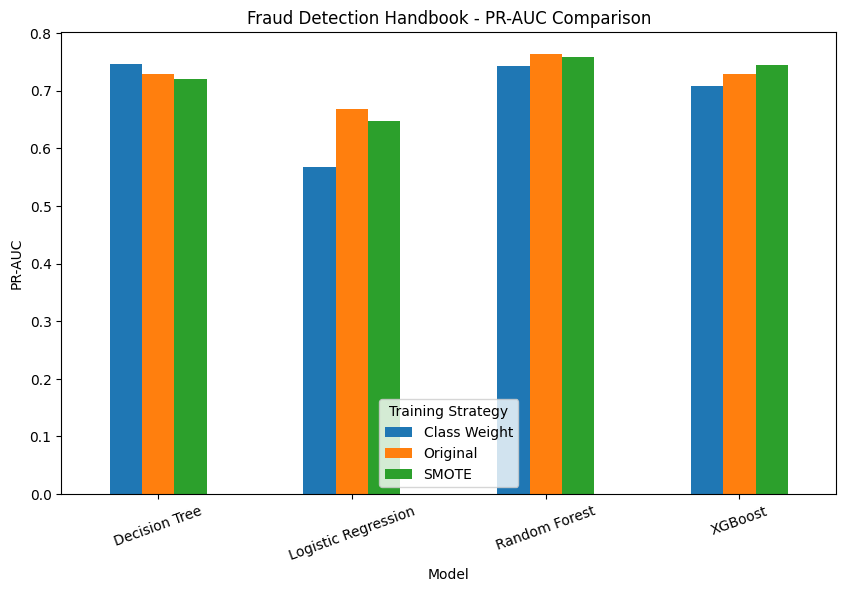

In [ ]:
# ============================================================
# 23. MODEL PERFORMANCE GRAPH - PRIMARY DATASET
# ============================================================

primary_plot = (
    primary_ml_results
    .pivot(
        index="Model",
        columns="Strategy",
        values="PR_AUC"
    )
)


primary_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Fraud Detection Handbook - PR-AUC Comparison"
)

plt.xlabel("Model")
plt.ylabel("PR-AUC")
plt.xticks(rotation=20)
plt.legend(title="Training Strategy")
plt.show()

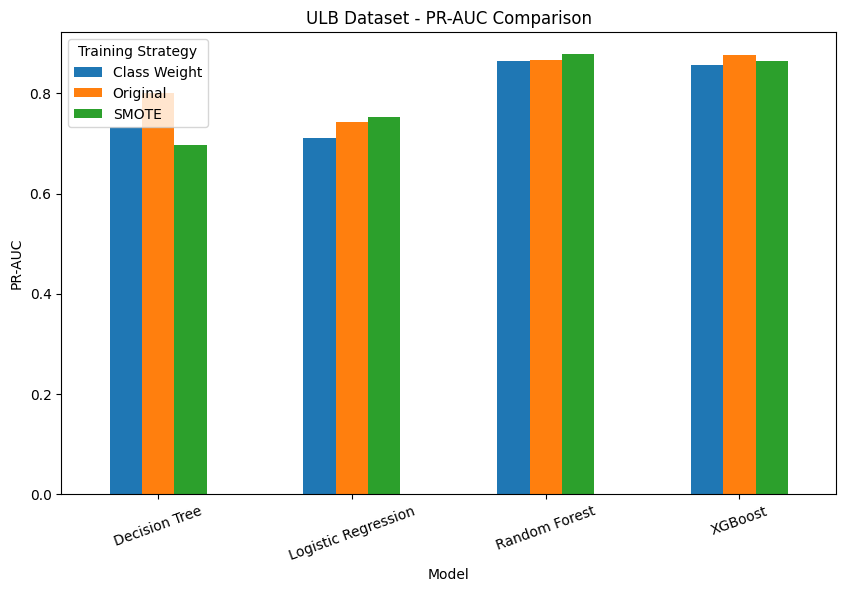

In [ ]:
# ============================================================
# 24. MODEL PERFORMANCE GRAPH - ULB
# ============================================================

ulb_plot = (
    results[
        results["Dataset"] == "ULB"
    ]
    .pivot(
        index="Model",
        columns="Strategy",
        values="PR_AUC"
    )
)


ulb_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "ULB Dataset - PR-AUC Comparison"
)

plt.xlabel("Model")
plt.ylabel("PR-AUC")
plt.xticks(rotation=20)
plt.legend(title="Training Strategy")
plt.show()

In [ ]:
# ============================================================
# 25. BEST MODEL FROM EACH DATASET
# ============================================================

print("\n" + "=" * 70)
print("VALIDATION-SELECTED BEST MODELS")
print("=" * 70)


for dataset_name in best_overall_information:

    information = (
        best_overall_information[
            dataset_name
        ]
    )

    print(
        "\nDataset:",
        dataset_name
    )

    print(
        "Best model:",
        information["model_name"]
    )

    print(
        "Best imbalance strategy:",
        information["strategy"]
    )

    print(
        "Validation PR-AUC:",
        round(
            information[
                "validation_score"
            ],
            4
        )
    )

    print(
        "Selected threshold:",
        round(
            information[
                "threshold"
            ],
            4
        )
    )


VALIDATION-SELECTED BEST MODELS

Dataset: Fraud Detection Handbook
Best model: Random Forest
Best imbalance strategy: Original
Validation PR-AUC: 0.7589
Selected threshold: 0.4905

Dataset: ULB
Best model: XGBoost
Best imbalance strategy: Original
Validation PR-AUC: 0.8268
Selected threshold: 0.2815


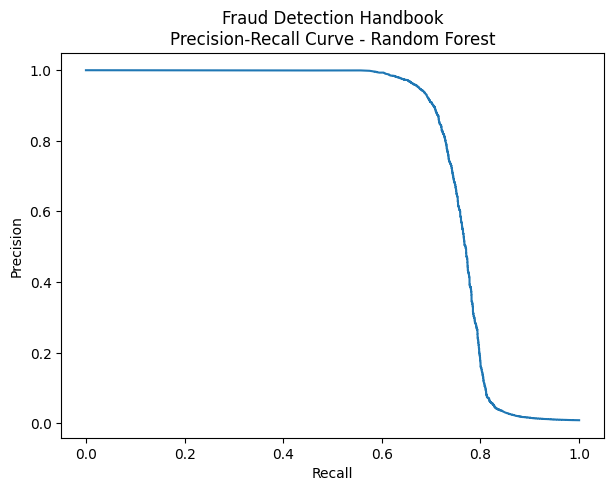

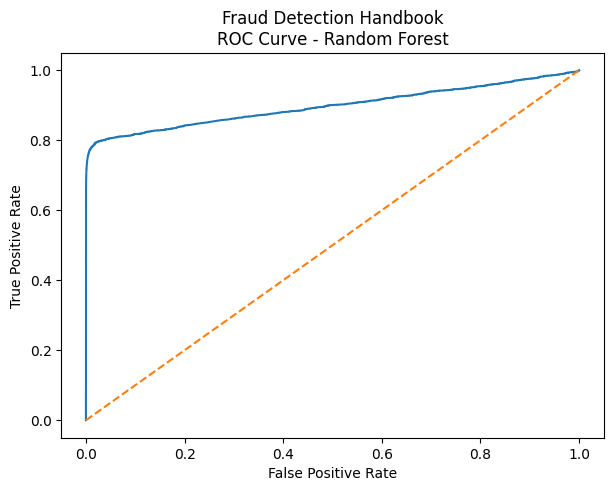

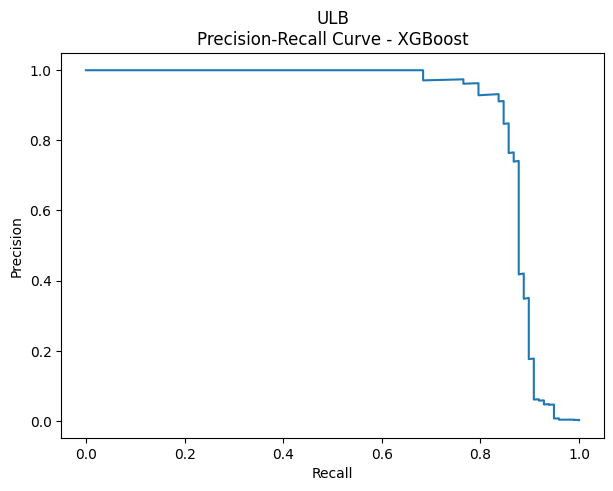

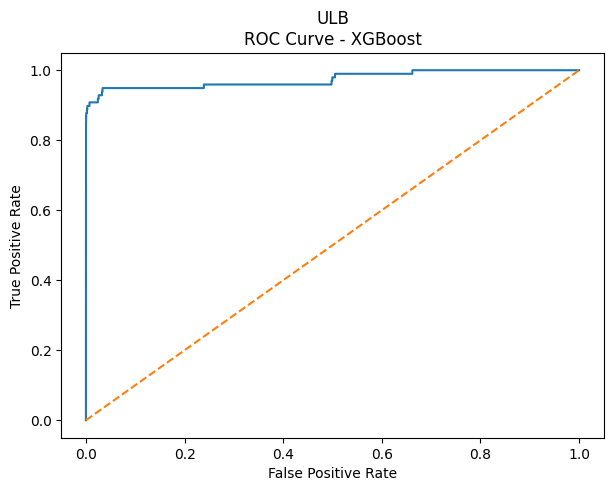

In [ ]:
# ============================================================
# 26. PRECISION-RECALL AND ROC CURVES FOR BEST MODELS
# ============================================================

for dataset_information in datasets:

    dataset_name = (
        dataset_information[
            "name"
        ]
    )

    target_column = (
        dataset_information[
            "target"
        ]
    )

    test_data = (
        dataset_information[
            "test"
        ]
    )

    y_test = (
        test_data[
            target_column
        ].astype(int)
    )


    probability = (
        best_overall_probability[
            dataset_name
        ]
    )


    information = (
        best_overall_information[
            dataset_name
        ]
    )


    precision_values, \
    recall_values, \
    _ = precision_recall_curve(
        y_test,
        probability
    )


    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        recall_values,
        precision_values
    )

    plt.title(
        dataset_name
        +
        "\nPrecision-Recall Curve - "
        +
        information[
            "model_name"
        ]
    )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.show()


    false_positive_values, \
    true_positive_values, \
    _ = roc_curve(
        y_test,
        probability
    )


    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        false_positive_values,
        true_positive_values
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.title(
        dataset_name
        +
        "\nROC Curve - "
        +
        information[
            "model_name"
        ]
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.show()

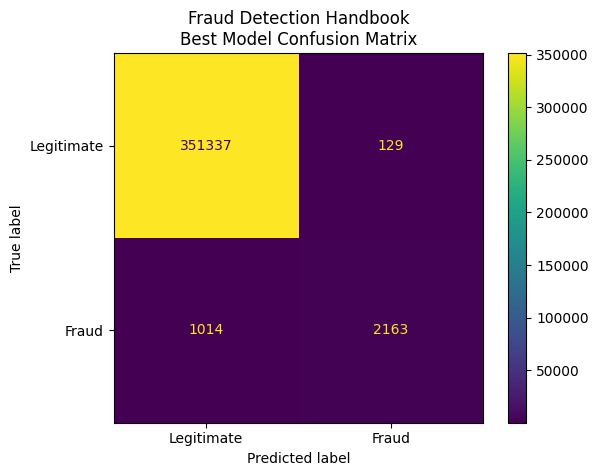

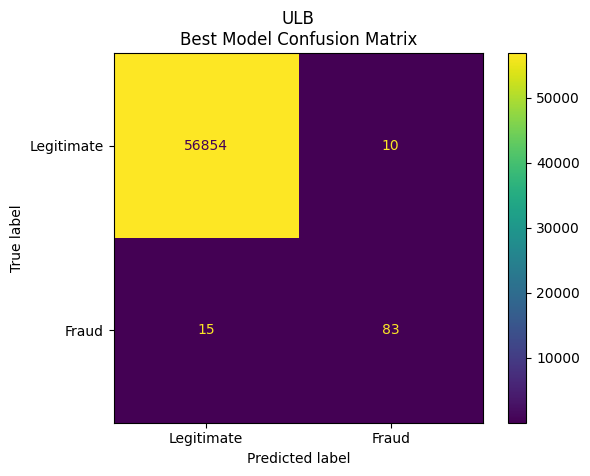

In [ ]:
# ============================================================
# 27. CONFUSION MATRIX FOR BEST MODELS
# ============================================================

for dataset_information in datasets:

    dataset_name = (
        dataset_information[
            "name"
        ]
    )

    target_column = (
        dataset_information[
            "target"
        ]
    )

    test_data = (
        dataset_information[
            "test"
        ]
    )

    y_test = (
        test_data[
            target_column
        ].astype(int)
    )


    probability = (
        best_overall_probability[
            dataset_name
        ]
    )


    threshold = (
        best_overall_information[
            dataset_name
        ]["threshold"]
    )


    prediction = (
        probability
        >=
        threshold
    ).astype(int)


    ConfusionMatrixDisplay.from_predictions(

        y_test,

        prediction,

        display_labels=[
            "Legitimate",
            "Fraud"
        ],

        values_format="d"
    )


    plt.title(
        dataset_name
        +
        "\nBest Model Confusion Matrix"
    )

    plt.show()

In [ ]:
# ============================================================
# 28. LOGISTIC REGRESSION COEFFICIENTS
# ============================================================

for dataset_information in datasets:

    dataset_name = (
        dataset_information[
            "name"
        ]
    )

    key = (
        dataset_name,
        "Logistic Regression"
    )

    information = (
        best_model_per_algorithm[
            key
        ]
    )

    pipeline = (
        information["model"]
    )

    feature_columns = (
        information["features"]
    )

    logistic_model = (
        pipeline.named_steps[
            "model"
        ]
    )


    coefficients = (
        pd.DataFrame(
            {
                "Feature":
                    feature_columns,

                "Coefficient":
                    logistic_model
                    .coef_[0]
            }
        )
    )


    coefficients[
        "Absolute_Coefficient"
    ] = abs(
        coefficients[
            "Coefficient"
        ]
    )


    coefficients = (
        coefficients
        .sort_values(
            "Absolute_Coefficient",
            ascending=False
        )
    )


    print(
        "\n",
        dataset_name,
        "- Logistic Regression coefficients"
    )

    display(
        coefficients.head(15)
    )


 Fraud Detection Handbook - Logistic Regression coefficients


,Feature,Coefficient,Absolute_Coefficient
8,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,-2.833005,2.833005
0,TX_AMOUNT,1.474282,1.474282
6,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,1.444066,1.444066
12,TERMINAL_ID_RISK_7DAY_WINDOW,0.911370,0.911370
14,TERMINAL_ID_RISK_30DAY_WINDOW,-0.559009,0.559009
5,CUSTOMER_ID_NB_TX_7DAY_WINDOW,0.175833,0.175833
4,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,0.130477,0.130477
10,TERMINAL_ID_RISK_1DAY_WINDOW,0.113545,0.113545
7,CUSTOMER_ID_NB_TX_30DAY_WINDOW,-0.078539,0.078539
11,TERMINAL_ID_NB_TX_7DAY_WINDOW,0.030873,0.030873



 ULB - Logistic Regression coefficients


,Feature,Coefficient,Absolute_Coefficient
4,V4,1.034017,1.034017
10,V10,-0.809146,0.809146
14,V14,-0.604088,0.604088
22,V22,0.515468,0.515468
13,V13,-0.511799,0.511799
9,V9,-0.341581,0.341581
16,V16,-0.321313,0.321313
20,V20,-0.313409,0.313409
21,V21,0.304828,0.304828
27,V27,-0.259043,0.259043



Fraud Detection Handbook - DECISION TREE RULES
|--- TERMINAL_ID_RISK_7DAY_WINDOW <= 0.15
|   |--- TX_AMOUNT <= 166.04
|   |   |--- CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW <= 126.52
|   |   |   |--- CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW <= 31.45
|   |   |   |   |--- TX_AMOUNT <= 48.34
|   |   |   |   |   |--- truncated branch of depth 11
|   |   |   |   |--- TX_AMOUNT >  48.34
|   |   |   |   |   |--- truncated branch of depth 11
|   |   |   |--- CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW >  31.45
|   |   |   |   |--- TERMINAL_ID_RISK_1DAY_WINDOW <= 0.58
|   |   |   |   |   |--- truncated branch of depth 11
|   |   |   |   |--- TERMINAL_ID_RISK_1DAY_WINDOW >  0.58
|   |   |   |   |   |--- truncated branch of depth 5
|   |   |--- CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW >  126.52
|   |   |   |--- CUSTOMER_ID_NB_TX_30DAY_WINDOW <= 3.50
|   |   |   |   |--- class: 0
|   |   |   |--- CUSTOMER_ID_NB_TX_30DAY_WINDOW >  3.50
|   |   |   |   |--- CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW <= 100.07
|   |   |   |   |   |

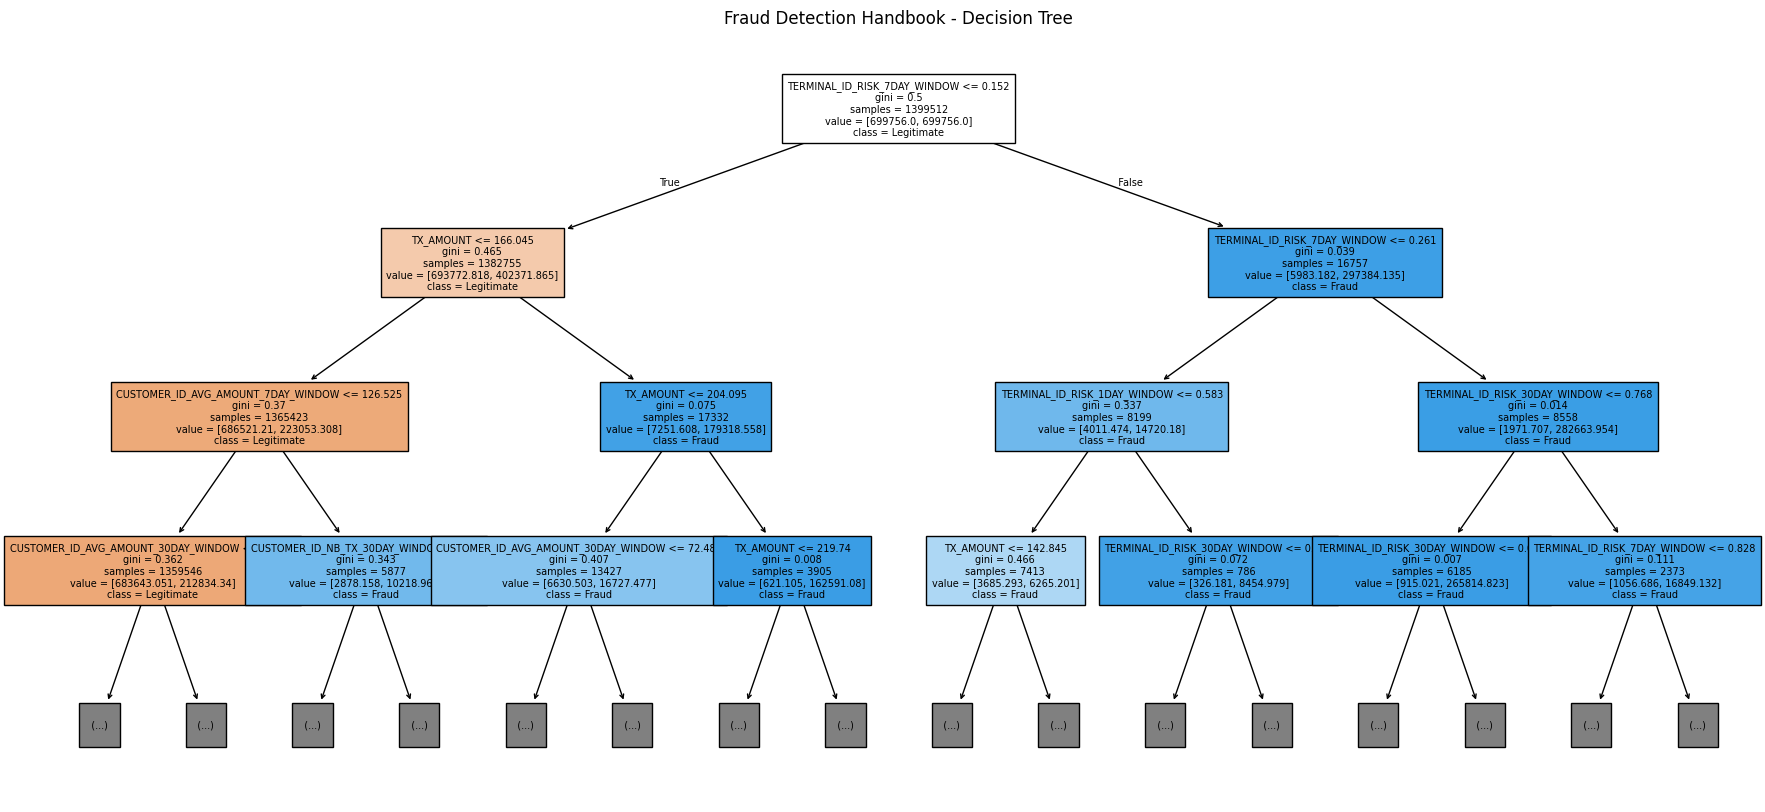


ULB - DECISION TREE RULES
|--- V17 <= -2.70
|   |--- V12 <= -2.18
|   |   |--- V26 <= -0.23
|   |   |   |--- V27 <= 0.91
|   |   |   |   |--- V14 <= -3.96
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- V14 >  -3.96
|   |   |   |   |   |--- class: 0
|   |   |   |--- V27 >  0.91
|   |   |   |   |--- class: 0
|   |   |--- V26 >  -0.23
|   |   |   |--- V4 <= 1.72
|   |   |   |   |--- class: 1
|   |   |   |--- V4 >  1.72
|   |   |   |   |--- V14 <= -4.34
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |--- V14 >  -4.34
|   |   |   |   |   |--- class: 1
|   |--- V12 >  -2.18
|   |   |--- class: 0
|--- V17 >  -2.70
|   |--- V14 <= -7.75
|   |   |--- class: 1
|   |--- V14 >  -7.75
|   |   |--- V14 <= -4.66
|   |   |   |--- V10 <= -1.85
|   |   |   |   |--- class: 1
|   |   |   |--- V10 >  -1.85
|   |   |   |   |--- V15 <= 0.06
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- V15 >  0.06
|   |   |   |   |   |--- class: 0
|   |   |--- V14 > 

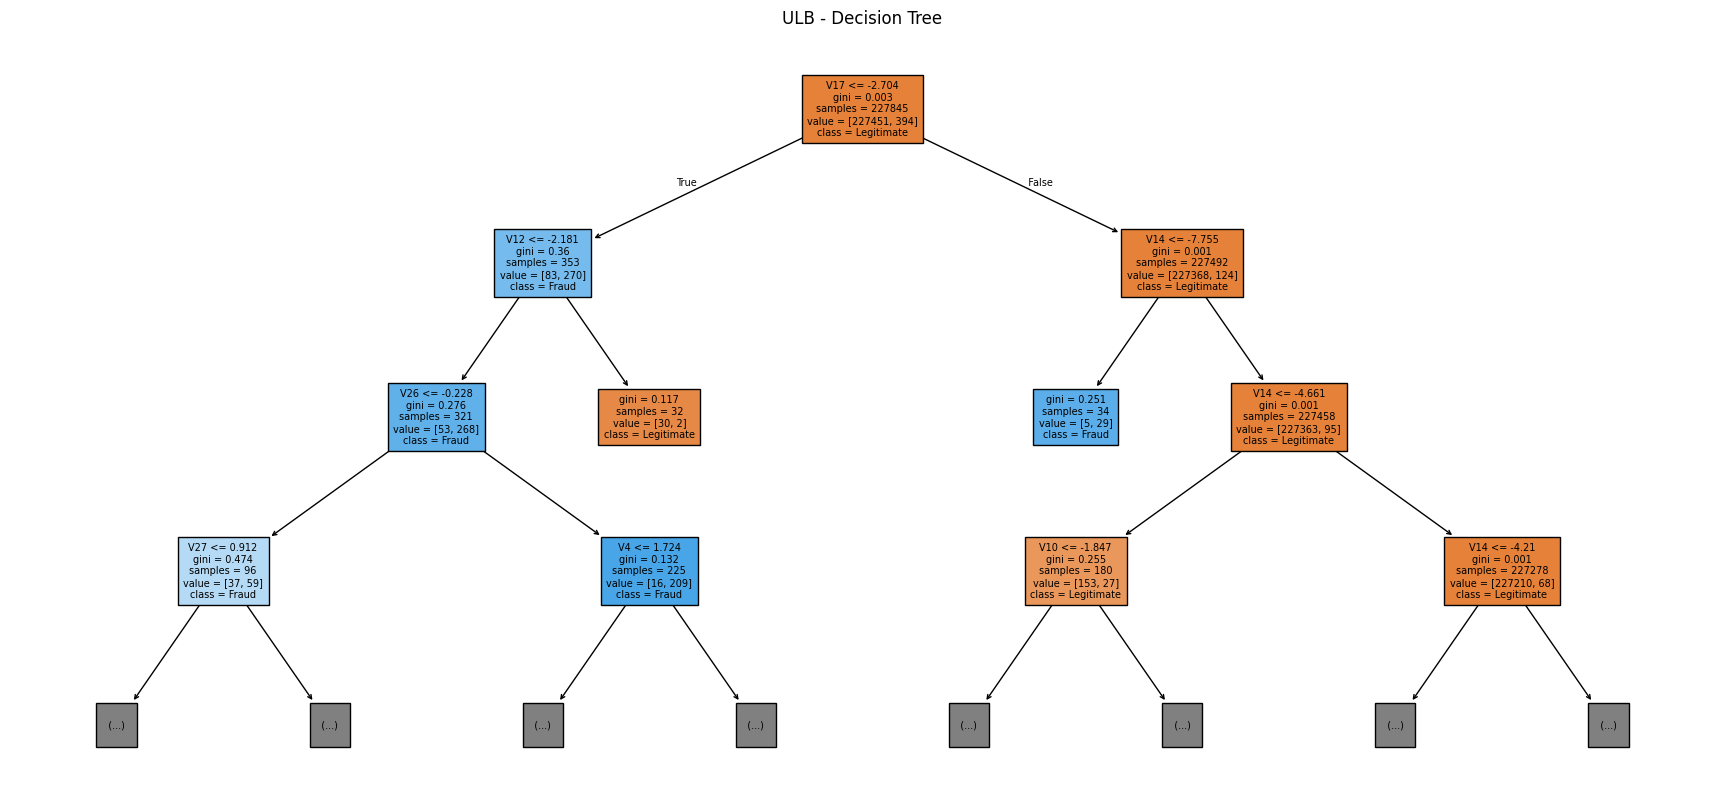

In [ ]:
# ============================================================
# 29. DECISION TREE RULES AND TREE VISUALISATION
# ============================================================

for dataset_information in datasets:

    dataset_name = (
        dataset_information[
            "name"
        ]
    )

    key = (
        dataset_name,
        "Decision Tree"
    )

    information = (
        best_model_per_algorithm[
            key
        ]
    )

    pipeline = (
        information["model"]
    )

    feature_columns = (
        information["features"]
    )

    tree_model = (
        pipeline.named_steps[
            "model"
        ]
    )


    print(
        "\n",
        "=" * 70
    )

    print(
        dataset_name,
        "- DECISION TREE RULES"
    )

    print(
        "=" * 70
    )


    print(
        export_text(
            tree_model,
            feature_names=
                feature_columns,
            max_depth=4
        )
    )


    plt.figure(
        figsize=(22, 10)
    )


    plot_tree(

        tree_model,

        feature_names=
            feature_columns,

        class_names=[
            "Legitimate",
            "Fraud"
        ],

        max_depth=3,

        filled=True,

        fontsize=7
    )


    plt.title(
        dataset_name
        +
        " - Decision Tree"
    )

    plt.show()


 Fraud Detection Handbook - Random Forest Feature Importance


,Feature,Importance
0,TX_AMOUNT,0.327139
12,TERMINAL_ID_RISK_7DAY_WINDOW,0.294085
14,TERMINAL_ID_RISK_30DAY_WINDOW,0.136822
8,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,0.067508
10,TERMINAL_ID_RISK_1DAY_WINDOW,0.040689
4,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,0.036346
6,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,0.028354
13,TERMINAL_ID_NB_TX_30DAY_WINDOW,0.017281
7,CUSTOMER_ID_NB_TX_30DAY_WINDOW,0.014597
5,CUSTOMER_ID_NB_TX_7DAY_WINDOW,0.012771


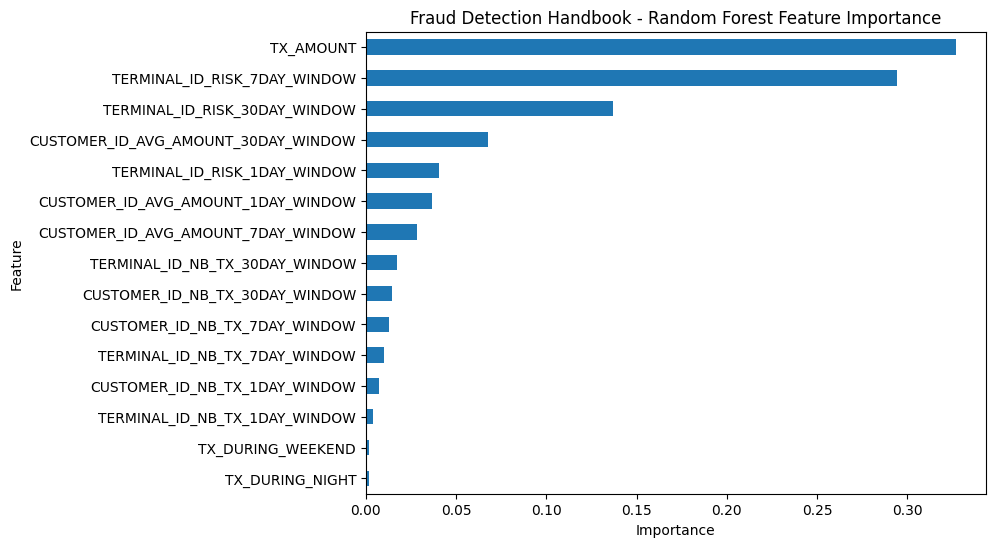


 ULB - Random Forest Feature Importance


,Feature,Importance
17,V17,0.421769
12,V12,0.170141
14,V14,0.124111
10,V10,0.050705
26,V26,0.035907
7,V7,0.027123
4,V4,0.016785
21,V21,0.014006
11,V11,0.013107
9,V9,0.012819


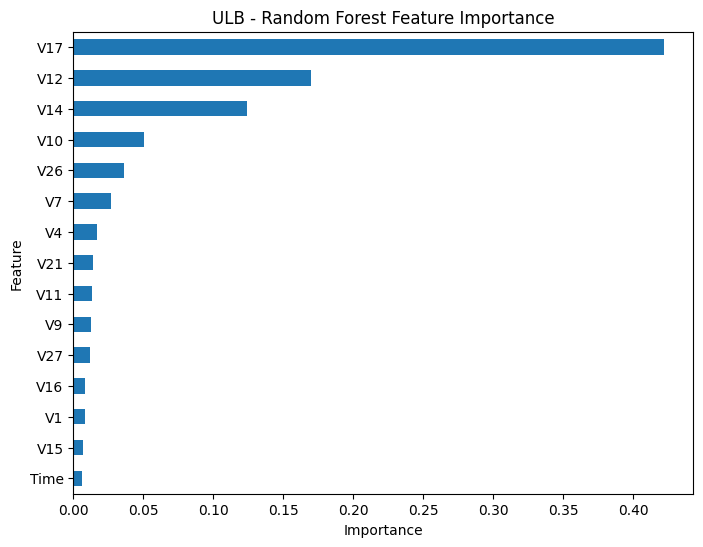

In [ ]:
# ============================================================
# 30. RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

for dataset_information in datasets:

    dataset_name = (
        dataset_information[
            "name"
        ]
    )

    key = (
        dataset_name,
        "Random Forest"
    )

    information = (
        best_model_per_algorithm[
            key
        ]
    )

    pipeline = (
        information["model"]
    )

    feature_columns = (
        information["features"]
    )

    rf_model = (
        pipeline.named_steps[
            "model"
        ]
    )


    rf_importance = (
        pd.DataFrame(
            {
                "Feature":
                    feature_columns,

                "Importance":
                    rf_model
                    .feature_importances_
            }
        )
        .sort_values(
            "Importance",
            ascending=False
        )
    )


    print(
        "\n",
        dataset_name,
        "- Random Forest Feature Importance"
    )


    display(
        rf_importance.head(15)
    )


    rf_importance.head(15).sort_values(
        "Importance"
    ).plot(
        kind="barh",
        x="Feature",
        y="Importance",
        figsize=(8, 6),
        legend=False
    )


    plt.title(
        dataset_name
        +
        " - Random Forest Feature Importance"
    )

    plt.xlabel("Importance")
    plt.show()


 Fraud Detection Handbook - XGBoost Feature Importance


,Feature,Importance
12,TERMINAL_ID_RISK_7DAY_WINDOW,0.347388
0,TX_AMOUNT,0.195447
1,TX_DURING_WEEKEND,0.100920
9,TERMINAL_ID_NB_TX_1DAY_WINDOW,0.094567
2,TX_DURING_NIGHT,0.072902
3,CUSTOMER_ID_NB_TX_1DAY_WINDOW,0.047223
10,TERMINAL_ID_RISK_1DAY_WINDOW,0.033014
14,TERMINAL_ID_RISK_30DAY_WINDOW,0.030940
8,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,0.026146
11,TERMINAL_ID_NB_TX_7DAY_WINDOW,0.019352


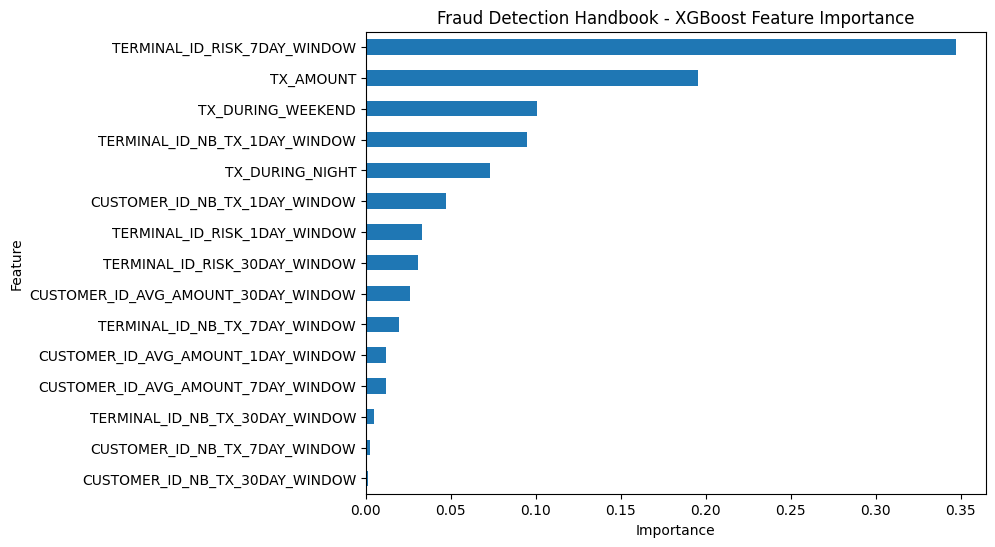


 ULB - XGBoost Feature Importance


,Feature,Importance
14,V14,0.518197
10,V10,0.110078
12,V12,0.047002
4,V4,0.025501
17,V17,0.018372
16,V16,0.017956
7,V7,0.015724
28,V28,0.015123
26,V26,0.013898
1,V1,0.013404


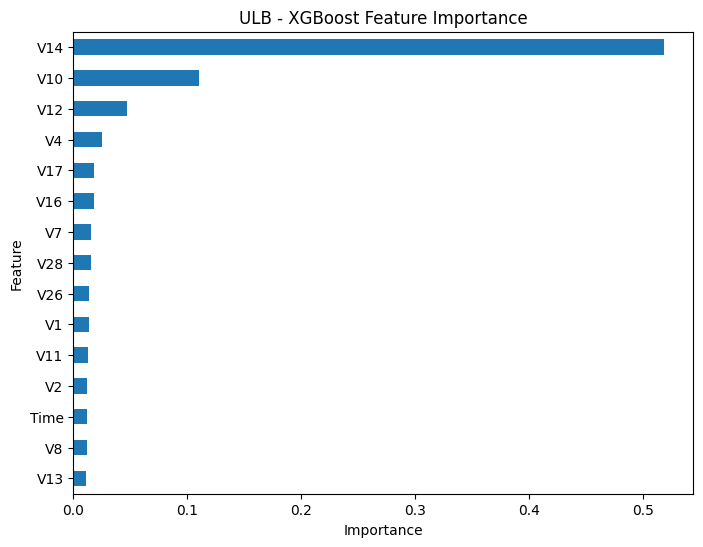

In [ ]:
# ============================================================
# 31. XGBOOST FEATURE IMPORTANCE
# ============================================================

for dataset_information in datasets:

    dataset_name = (
        dataset_information[
            "name"
        ]
    )

    key = (
        dataset_name,
        "XGBoost"
    )

    information = (
        best_model_per_algorithm[
            key
        ]
    )

    pipeline = (
        information["model"]
    )

    feature_columns = (
        information["features"]
    )

    xgb_model = (
        pipeline.named_steps[
            "model"
        ]
    )


    xgb_importance = (
        pd.DataFrame(
            {
                "Feature":
                    feature_columns,

                "Importance":
                    xgb_model
                    .feature_importances_
            }
        )
        .sort_values(
            "Importance",
            ascending=False
        )
    )


    print(
        "\n",
        dataset_name,
        "- XGBoost Feature Importance"
    )


    display(
        xgb_importance.head(15)
    )


    xgb_importance.head(15).sort_values(
        "Importance"
    ).plot(
        kind="barh",
        x="Feature",
        y="Importance",
        figsize=(8, 6),
        legend=False
    )


    plt.title(
        dataset_name
        +
        " - XGBoost Feature Importance"
    )

    plt.xlabel("Importance")
    plt.show()

In [ ]:
# ============================================================
# 32. SHAP EXPLANATION - RANDOM FOREST
# ============================================================

for dataset_information in datasets:

    dataset_name = (
        dataset_information[
            "name"
        ]
    )

    key = (
        dataset_name,
        "Random Forest"
    )

    information = (
        best_model_per_algorithm[
            key
        ]
    )

    pipeline = (
        information["model"]
    )

    feature_columns = (
        information["features"]
    )

    X_test = (
        information["X_test"]
    )


    sample_size = min(
        1000,
        len(X_test)
    )


    X_sample = (
        X_test.sample(
            n=sample_size,
            random_state=RANDOM_STATE
        )
    )


    # Apply the fitted imputer.

    X_sample_processed = (
        pipeline.named_steps[
            "imputer"
        ]
        .transform(
            X_sample
        )
    )


    rf_model = (
        pipeline.named_steps[
            "model"
        ]
    )


    rf_explainer = (
        shap.TreeExplainer(
            rf_model
        )
    )


    rf_shap_values = (
        rf_explainer
        .shap_values(
            X_sample_processed
        )
    )


    # Different SHAP versions may return
    # a list or a 3-dimensional array.

    if isinstance(
        rf_shap_values,
        list
    ):

        rf_values = (
            rf_shap_values[1]
        )

    else:

        rf_values = np.asarray(
            rf_shap_values
        )

        if rf_values.ndim == 3:

            rf_values = (
                rf_values[:, :, 1]
            )


    shap.summary_plot(

        rf_values,

        X_sample_processed,

        feature_names=
            feature_columns,

        plot_type="bar",

        max_display=15,

        show=False
    )


    plt.title(
        dataset_name
        +
        " - Random Forest SHAP Importance"
    )

    plt.show()

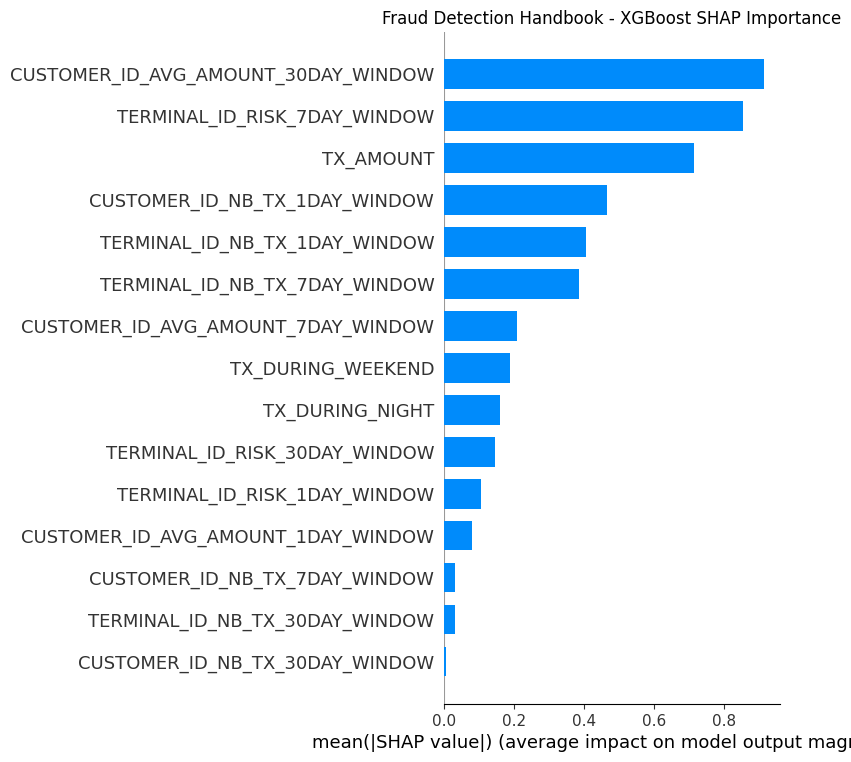

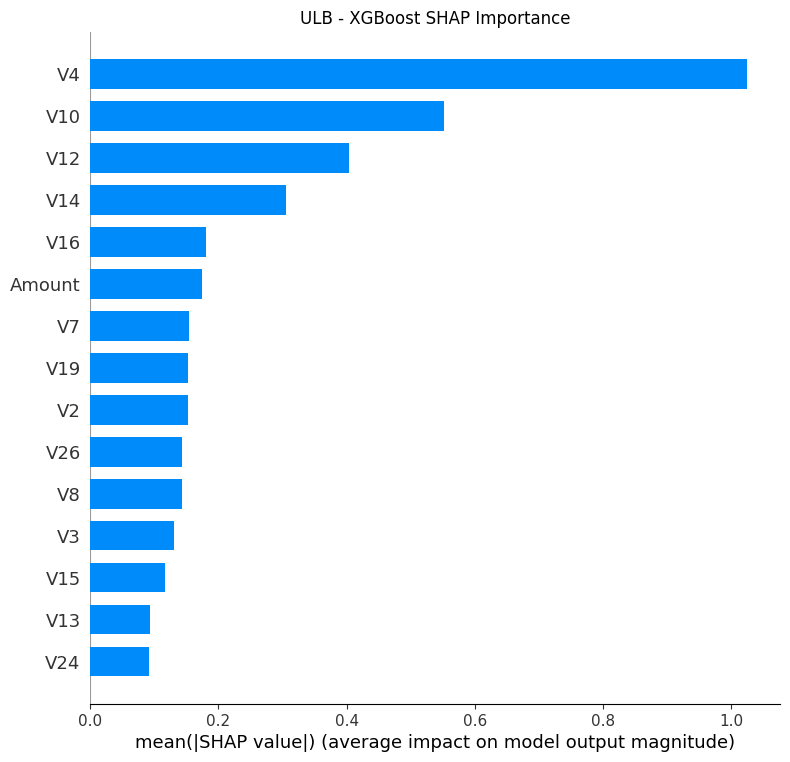

In [ ]:
# ============================================================
# 33. SHAP EXPLANATION - XGBOOST
# ============================================================

for dataset_information in datasets:

    dataset_name = (
        dataset_information[
            "name"
        ]
    )

    key = (
        dataset_name,
        "XGBoost"
    )

    information = (
        best_model_per_algorithm[
            key
        ]
    )

    pipeline = (
        information["model"]
    )

    feature_columns = (
        information["features"]
    )

    X_test = (
        information["X_test"]
    )


    sample_size = min(
        1000,
        len(X_test)
    )


    X_sample = (
        X_test.sample(
            n=sample_size,
            random_state=RANDOM_STATE
        )
    )


    X_sample_processed = (
        pipeline.named_steps[
            "imputer"
        ]
        .transform(
            X_sample
        )
    )


    xgb_model = (
        pipeline.named_steps[
            "model"
        ]
    )


    xgb_explainer = (
        shap.TreeExplainer(
            xgb_model
        )
    )


    xgb_shap_values = (
        xgb_explainer
        .shap_values(
            X_sample_processed
        )
    )


    xgb_values = np.asarray(
        xgb_shap_values
    )


    if xgb_values.ndim == 3:

        xgb_values = (
            xgb_values[:, :, 1]
        )


    shap.summary_plot(

        xgb_values,

        X_sample_processed,

        feature_names=
            feature_columns,

        plot_type="bar",

        max_display=15,

        show=False
    )


    plt.title(
        dataset_name
        +
        " - XGBoost SHAP Importance"
    )

    plt.show()

In [ ]:
# ============================================================
# 34. BEST TRAINING STRATEGY FOR EACH ALGORITHM
# ============================================================

best_algorithm_results = (
    results
    .sort_values(
        "Validation_PR_AUC",
        ascending=False
    )
    .groupby(
        [
            "Dataset",
            "Model"
        ],
        as_index=False
    )
    .first()
)


print(
    "\nBest imbalance strategy for each algorithm:"
)


display(
    best_algorithm_results[
        [
            "Dataset",
            "Model",
            "Strategy",
            "Validation_PR_AUC",
            "PR_AUC",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "False_Positive_Rate",
            "Training_Time_Seconds"
        ]
    ]
    .round(4)
)


Best imbalance strategy for each algorithm:


,Dataset,Model,Strategy,Validation_PR_AUC,PR_AUC,Precision,Recall,F1,ROC_AUC,False_Positive_Rate,Training_Time_Seconds
0,Fraud Detection Handbook,Decision Tree,Class Weight,0.7399,0.7469,0.8980,0.6736,0.7698,0.8870,0.0007,28.7969
1,Fraud Detection Handbook,Logistic Regression,Original,0.6618,0.6676,0.7519,0.6172,0.6780,0.8934,0.0018,7.0184
2,Fraud Detection Handbook,Random Forest,Original,0.7589,0.7635,0.9437,0.6808,0.7910,0.8973,0.0004,250.8435
3,Fraud Detection Handbook,XGBoost,SMOTE,0.7393,0.7446,0.9408,0.6506,0.7693,0.9045,0.0004,7.0489
4,ULB,Decision Tree,Original,0.7284,0.8004,0.8750,0.5714,0.6914,0.9320,0.0001,16.0159
5,ULB,Logistic Regression,Original,0.7093,0.7428,0.6585,0.8265,0.7330,0.9571,0.0007,1.9442
6,ULB,Random Forest,Original,0.8068,0.8660,0.9121,0.8469,0.8783,0.9760,0.0001,98.0366
7,ULB,XGBoost,Original,0.8268,0.8759,0.8925,0.8469,0.8691,0.9741,0.0002,1.8197



Cross-dataset PR-AUC comparison:


Dataset,Fraud Detection Handbook,ULB
Model,,
Decision Tree,0.7469,0.8004
Logistic Regression,0.6676,0.7428
Random Forest,0.7635,0.8660
XGBoost,0.7446,0.8759


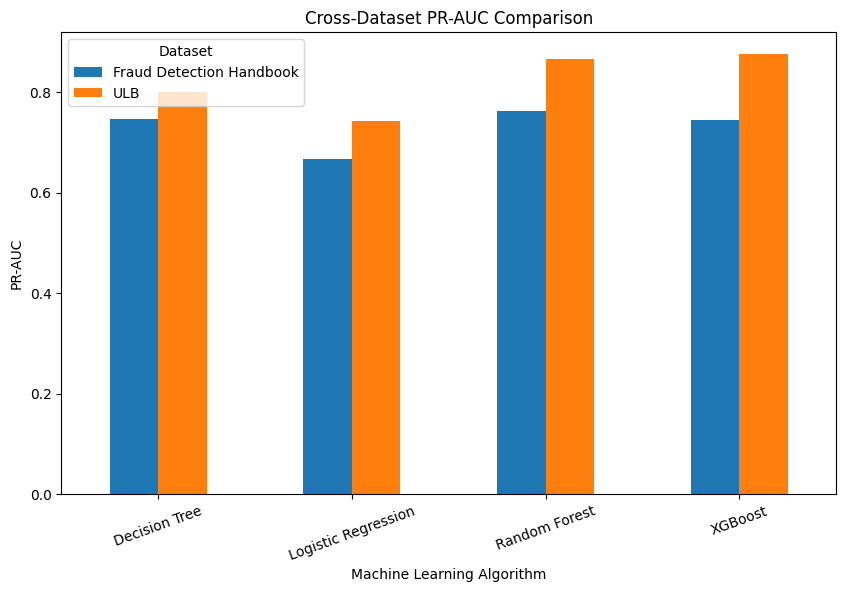

In [ ]:
# ============================================================
# 35. CROSS-DATASET MODEL COMPARISON
# ============================================================

cross_dataset_comparison = (
    best_algorithm_results
    .pivot(
        index="Model",
        columns="Dataset",
        values="PR_AUC"
    )
)


print(
    "\nCross-dataset PR-AUC comparison:"
)

display(
    cross_dataset_comparison.round(4)
)


cross_dataset_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Cross-Dataset PR-AUC Comparison"
)

plt.ylabel(
    "PR-AUC"
)

plt.xlabel(
    "Machine Learning Algorithm"
)

plt.xticks(
    rotation=20
)

plt.show()

In [ ]:
# ============================================================
# 36. FINAL DISSERTATION RESULTS TABLE
# ============================================================

final_results_table = (
    results[
        [
            "Dataset",
            "Model",
            "Strategy",
            "PR_AUC",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "Specificity",
            "False_Positive_Rate",
            "Balanced_Accuracy",
            "MCC",
            "Accuracy",
            "Threshold",
            "Training_Time_Seconds",
            "Prediction_Time_Seconds",
            "TP",
            "FP",
            "TN",
            "FN",
            "Best_Parameters"
        ]
    ]
    .copy()
)


numeric_columns = (
    final_results_table
    .select_dtypes(
        include=np.number
    )
    .columns
)


final_results_table[
    numeric_columns
] = (
    final_results_table[
        numeric_columns
    ]
    .round(4)
)


print(
    "\n" + "=" * 70
)

print(
    "FINAL DISSERTATION MACHINE LEARNING RESULTS"
)

print(
    "=" * 70
)


display(
    final_results_table
)


FINAL DISSERTATION MACHINE LEARNING RESULTS


,Dataset,Model,Strategy,PR_AUC,Precision,Recall,F1,ROC_AUC,Specificity,False_Positive_Rate,...,MCC,Accuracy,Threshold,Training_Time_Seconds,Prediction_Time_Seconds,TP,FP,TN,FN,Best_Parameters
0,Fraud Detection Handbook,Random Forest,Original,0.7635,0.9437,0.6808,0.7910,0.8973,0.9996,0.0004,...,0.8001,0.9968,0.4905,250.8435,0.4471,2163,129,351337,1014,"{'model__max_depth': 20, 'model__max_features'..."
1,Fraud Detection Handbook,Random Forest,SMOTE,0.7593,0.9289,0.6745,0.7815,0.8976,0.9995,0.0005,...,0.7900,0.9966,0.6479,247.8027,0.5189,2143,164,351302,1034,"{'model__max_depth': 20, 'model__max_features'..."
2,Fraud Detection Handbook,Decision Tree,Class Weight,0.7469,0.8980,0.6736,0.7698,0.8870,0.9993,0.0007,...,0.7761,0.9964,0.9864,28.7969,0.0860,2140,243,351223,1037,"{'model__max_depth': 15, 'model__min_samples_l..."
3,Fraud Detection Handbook,XGBoost,SMOTE,0.7446,0.9408,0.6506,0.7693,0.9045,0.9996,0.0004,...,0.7808,0.9965,0.4584,7.0489,0.2074,2067,130,351336,1110,"{'model__learning_rate': 0.1, 'model__max_dept..."
4,Fraud Detection Handbook,Random Forest,Class Weight,0.7431,0.8251,0.6966,0.7554,0.8789,0.9987,0.0013,...,0.7561,0.9960,0.5685,231.6903,0.5651,2213,469,350997,964,"{'model__max_depth': 20, 'model__max_features'..."
5,Fraud Detection Handbook,Decision Tree,SMOTE,0.7202,0.9258,0.6519,0.7651,0.8782,0.9995,0.0005,...,0.7753,0.9964,0.8634,32.2122,0.0800,2071,166,351300,1106,"{'model__max_depth': 15, 'model__min_samples_l..."
6,Fraud Detection Handbook,Decision Tree,Original,0.7293,0.9035,0.6689,0.7687,0.8751,0.9994,0.0006,...,0.7757,0.9964,0.4100,25.9616,0.0802,2125,227,351239,1052,"{'model__max_depth': 15, 'model__min_samples_l..."
7,Fraud Detection Handbook,XGBoost,Original,0.7283,0.8376,0.6056,0.7030,0.9048,0.9989,0.0011,...,0.7101,0.9954,0.4306,8.8182,0.1993,1924,373,351093,1253,"{'model__learning_rate': 0.1, 'model__max_dept..."
8,Fraud Detection Handbook,XGBoost,Class Weight,0.7089,0.7304,0.6292,0.6760,0.9047,0.9979,0.0021,...,0.6752,0.9946,0.9802,5.9191,0.1990,1999,738,350728,1178,"{'model__learning_rate': 0.1, 'model__max_dept..."
9,Fraud Detection Handbook,Logistic Regression,Original,0.6676,0.7519,0.6172,0.6780,0.8934,0.9982,0.0018,...,0.6787,0.9947,0.2102,7.0184,0.1131,1961,647,350819,1216,{'model__C': 1}


In [ ]:
# ============================================================
# 37. FINAL BEST MODEL FOR EACH DATASET
# ============================================================

final_best_models = (
    results
    .sort_values(
        [
            "Dataset",
            "Validation_PR_AUC"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "Dataset",
        as_index=False
    )
    .first()
)


print(
    "\nFINAL VALIDATION-SELECTED MODEL FOR EACH DATASET:"
)


display(
    final_best_models[
        [
            "Dataset",
            "Model",
            "Strategy",
            "Validation_PR_AUC",
            "PR_AUC",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "Specificity",
            "False_Positive_Rate",
            "Balanced_Accuracy",
            "MCC",
            "Accuracy",
            "Threshold",
            "Best_Parameters"
        ]
    ]
    .round(4)
)


FINAL VALIDATION-SELECTED MODEL FOR EACH DATASET:


,Dataset,Model,Strategy,Validation_PR_AUC,PR_AUC,Precision,Recall,F1,ROC_AUC,Specificity,False_Positive_Rate,Balanced_Accuracy,MCC,Accuracy,Threshold,Best_Parameters
0,Fraud Detection Handbook,Random Forest,Original,0.7589,0.7635,0.9437,0.6808,0.7910,0.8973,0.9996,0.0004,0.8402,0.8001,0.9968,0.4905,"{'model__max_depth': 20, 'model__max_features'..."
1,ULB,XGBoost,Original,0.8268,0.8759,0.8925,0.8469,0.8691,0.9741,0.9998,0.0002,0.9234,0.8692,0.9996,0.2815,"{'model__learning_rate': 0.05, 'model__max_dep..."
